In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


def load_dataset(filename):
    BASE_DIR = r"C:\work\Port_Cast_Final\1.Rawdata_EDA\Data"
    FILE_PATH = BASE_DIR + "\\" + filename + ".csv"

    try:
        return pd.read_csv(FILE_PATH)
    except UnicodeDecodeError:
        return pd.read_csv(FILE_PATH, encoding="euc-kr")

In [8]:
df = load_dataset('weather_raw1')

In [9]:
df.head()

,항만,관측시각,최대순간풍속(m/s),파고_유의파고(m),파고_최대파고(m),풍속(m/s),풍향(8방위),강수량(mm),시정(10m)
0,북항,2020-01-01 0:00,4.25,NaN,NaN,2.50,북서,NaN,NaN
1,신항,2020-01-01 0:00,5.42,NaN,NaN,3.71,북서,NaN,NaN
2,북항,2020-01-01 1:00,3.93,0.5,0.7,1.70,북서,NaN,2000.0
3,신항,2020-01-01 1:00,4.48,NaN,NaN,3.16,북서,NaN,2000.0
4,북항,2020-01-01 2:00,3.88,0.4,0.5,1.00,북서,NaN,2000.0


| 구분 | 변수 |
|---|---|
| 항만별 관측지점이 다름 | 최대순간풍속, 유의파고, 최대파고, 풍속, 풍향 |
| 동일 관측지점 자료를 함께 사용 | 강수량, 시정 |

| 항만 | 풍향 관측지점 |
|---|---|
| 신항 | 이수도 |
| 북항 | 오륙도 |

In [10]:
df.dtypes

항만                 str
관측시각               str
최대순간풍속(m/s)    float64
파고_유의파고(m)     float64
파고_최대파고(m)     float64
풍속(m/s)        float64
풍향(8방위)            str
강수량(mm)        float64
시정(10m)        float64
dtype: object

In [11]:
# 관측시간 datetype 변경
df["관측시각"] = pd.to_datetime(df["관측시각"])

df.dtypes

항만                        str
관측시각           datetime64[us]
최대순간풍속(m/s)           float64
파고_유의파고(m)            float64
파고_최대파고(m)            float64
풍속(m/s)               float64
풍향(8방위)                   str
강수량(mm)               float64
시정(10m)               float64
dtype: object

In [12]:
df.columns.to_list()

['항만',
 '관측시각',
 '최대순간풍속(m/s)',
 '파고_유의파고(m)',
 '파고_최대파고(m)',
 '풍속(m/s)',
 '풍향(8방위)',
 '강수량(mm)',
 '시정(10m)']

In [13]:
df1 = df.copy()

In [14]:
df1 = df1[[
    "항만",
    "관측시각",
    "풍속(m/s)",
    "최대순간풍속(m/s)",
    "풍향(8방위)",
    "파고_유의파고(m)",
    "파고_최대파고(m)",
    "강수량(mm)",
    "시정(10m)",
]]

df1

,항만,관측시각,풍속(m/s),최대순간풍속(m/s),풍향(8방위),파고_유의파고(m),파고_최대파고(m),강수량(mm),시정(10m)
0,북항,2020-01-01 00:00:00,2.50,4.25,북서,NaN,NaN,NaN,NaN
1,신항,2020-01-01 00:00:00,3.71,5.42,북서,NaN,NaN,NaN,NaN
2,북항,2020-01-01 01:00:00,1.70,3.93,북서,0.5,0.7,NaN,2000.0
3,신항,2020-01-01 01:00:00,3.16,4.48,북서,NaN,NaN,NaN,2000.0
4,북항,2020-01-01 02:00:00,1.00,3.88,북서,0.4,0.5,NaN,2000.0
...,...,...,...,...,...,...,...,...,...
105203,신항,2025-12-31 21:00:00,4.74,6.35,북서,NaN,NaN,NaN,NaN
105204,북항,2025-12-31 22:00:00,1.50,5.12,서,NaN,NaN,NaN,NaN
105205,신항,2025-12-31 22:00:00,3.50,5.98,북서,NaN,NaN,NaN,NaN
105206,북항,2025-12-31 23:00:00,3.90,4.63,북서,NaN,NaN,NaN,NaN


In [15]:
# 기간설정 (2021~2024)
df["관측시각"] = pd.to_datetime(df["관측시각"])

df1 = df.loc[
    (df["관측시각"] >= "2021-01-01") &
    (df["관측시각"] < "2025-01-01")
].copy()


In [16]:
# 결측치 확인
df1.isna().sum()

# 강수량은 비 안오는날 고려해야해서 결측치 많은것임.
# 기상청 결측치는 추후 베이지안 네트워크로 예측모델 넣을것임.


항만                 0
관측시각               0
최대순간풍속(m/s)     3105
파고_유의파고(m)      1867
파고_최대파고(m)      1871
풍속(m/s)          868
풍향(8방위)          886
강수량(mm)        63345
시정(10m)          201
dtype: int64

In [17]:
df1.groupby("항만")[df1.select_dtypes(include="number").columns].describe()[
    [(col, stat)
     for col in df1.select_dtypes(include="number").columns
     for stat in ["min", "25%", "50%", "75%", "max"]]
].T.rename(columns={"북항": "북항", "신항": "신항"})

항만                    북항       신항
최대순간풍속(m/s) min     0.01     0.00
            25%     1.76     1.63
            50%     3.08     2.70
            75%     4.50     4.20
            max    15.68    22.79
파고_유의파고(m)  min     0.10     0.10
            25%     0.30     0.30
            50%     0.50     0.30
            75%     0.80     0.50
            max    10.80     4.90
파고_최대파고(m)  min     0.10     0.10
            25%     0.50     0.30
            50%     0.70     0.50
            75%     1.10     0.70
            max    17.20     8.30
풍속(m/s)     min     0.00     0.00
            25%     0.90     1.20
            50%     1.80     1.95
            75%     2.90     3.05
            max    11.10    16.13
강수량(mm)     min     0.00     0.00
            25%     0.00     0.00
            50%     0.30     0.30
            75%     1.80     1.80
            max    83.10    83.10
시정(10m)     min    11.00    11.00
            25%  2247.00  2247.00
            50%  4030.00  4030.00
            75%  5000.00  5000.00
            max  5000.00  5000.00

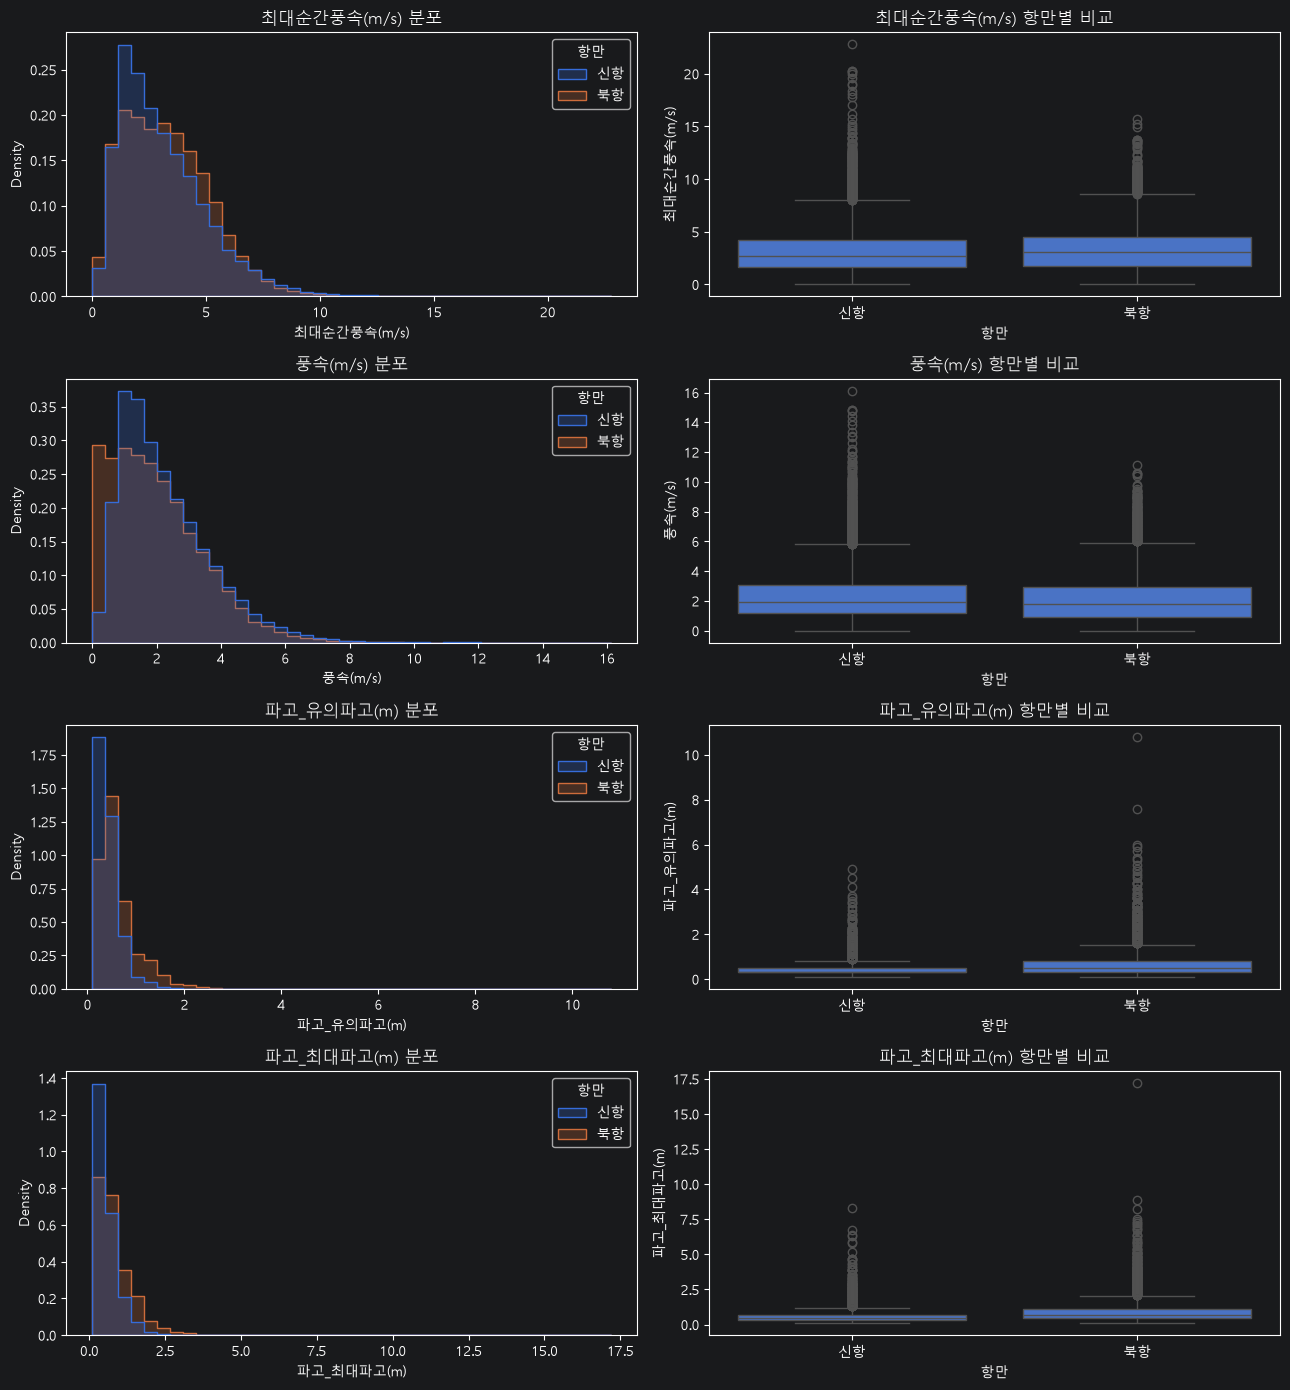

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns



# 1. 항만별 관측자료: 분포와 이상값 확인
columns = [
    "최대순간풍속(m/s)",
    "풍속(m/s)",
    "파고_유의파고(m)",
    "파고_최대파고(m)",
]

fig, axes = plt.subplots(len(columns), 2, figsize=(13, 14))

for i, col in enumerate(columns):
    sns.histplot(
        data=df1, x=col, hue="항만",
        bins=40, element="step", stat="density",
        common_norm=False, ax=axes[i, 0],
    )
    axes[i, 0].set_title(f"{col} 분포")

    sns.boxplot(
        data=df1, x="항만", y=col, ax=axes[i, 1],
    )
    axes[i, 1].set_title(f"{col} 항만별 비교")

plt.tight_layout()
plt.show()

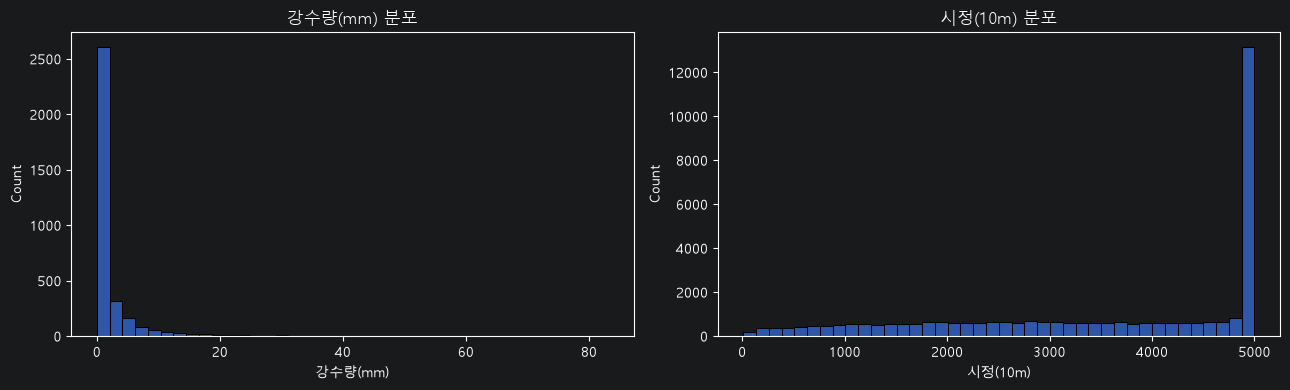

In [19]:
# 같은 관측시각의 공유 자료는 한 번만 사용
shared = df1.groupby("관측시각")[["강수량(mm)", "시정(10m)"]].first()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, shared.columns):
    sns.histplot(data=shared, x=col, bins=40, ax=ax)
    ax.set_title(f"{col} 분포")

plt.tight_layout()
plt.show()

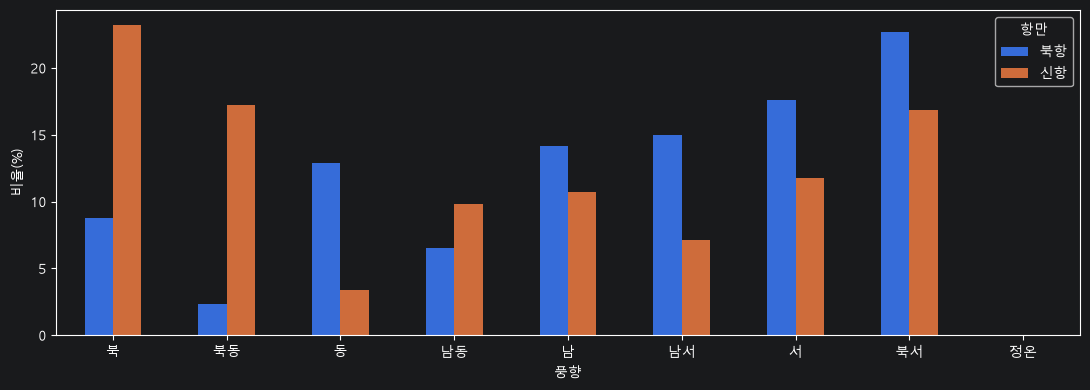

In [20]:
order = ["북", "북동", "동", "남동", "남", "남서", "서", "북서", "정온"]

wind_ratio = pd.crosstab(
    df1["풍향(8방위)"],
    df1["항만"],
    normalize="columns",
).reindex(order).fillna(0) * 100

wind_ratio.plot.bar(figsize=(11, 4))
plt.ylabel("비율(%)")
plt.xlabel("풍향")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

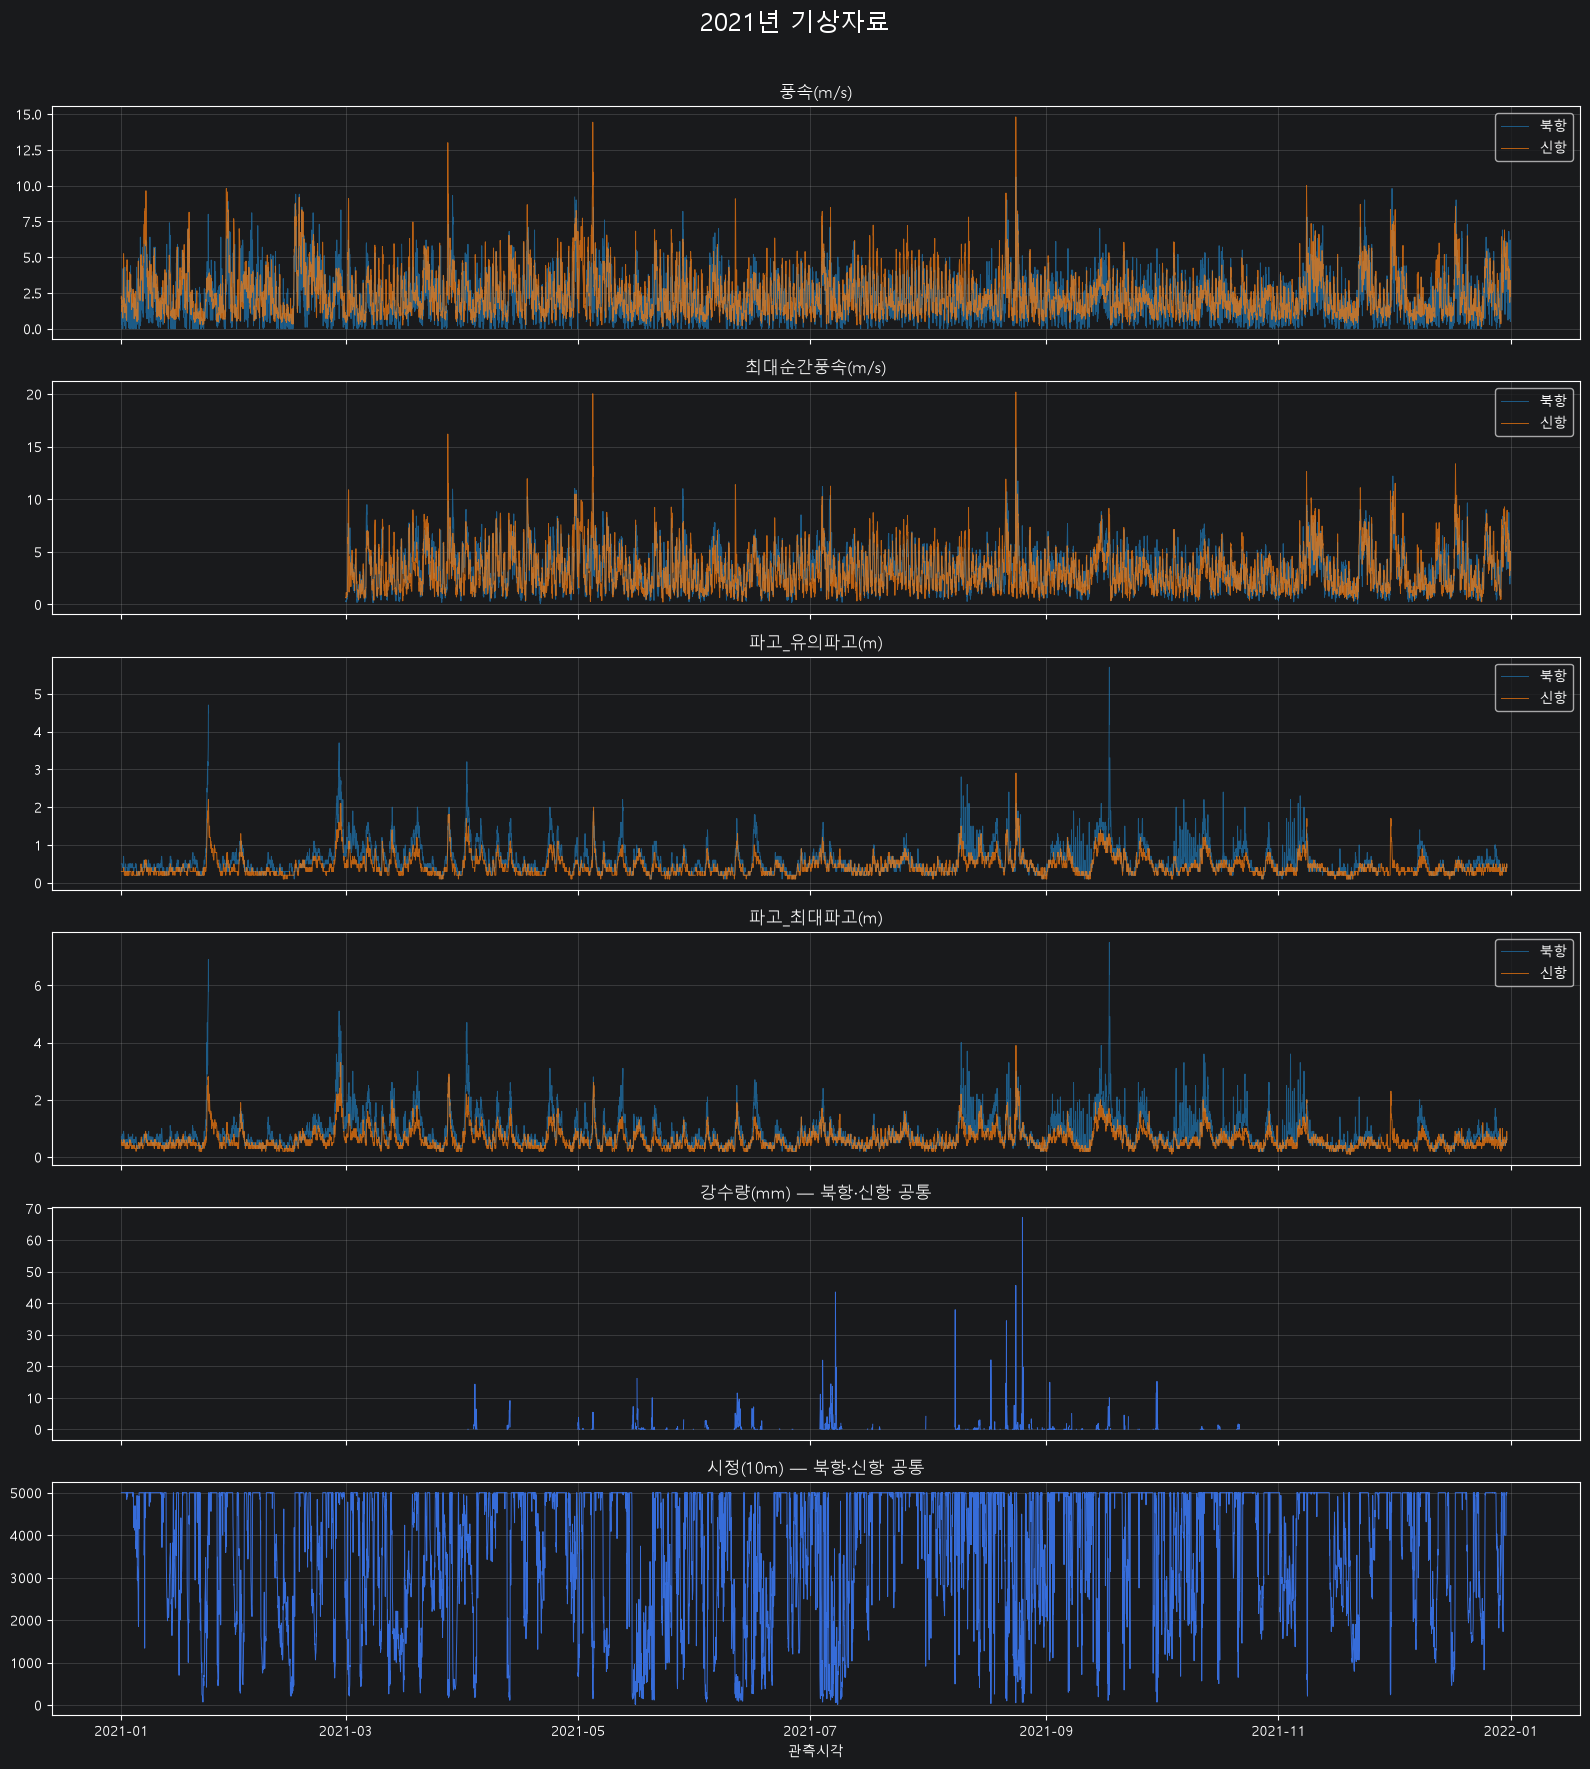

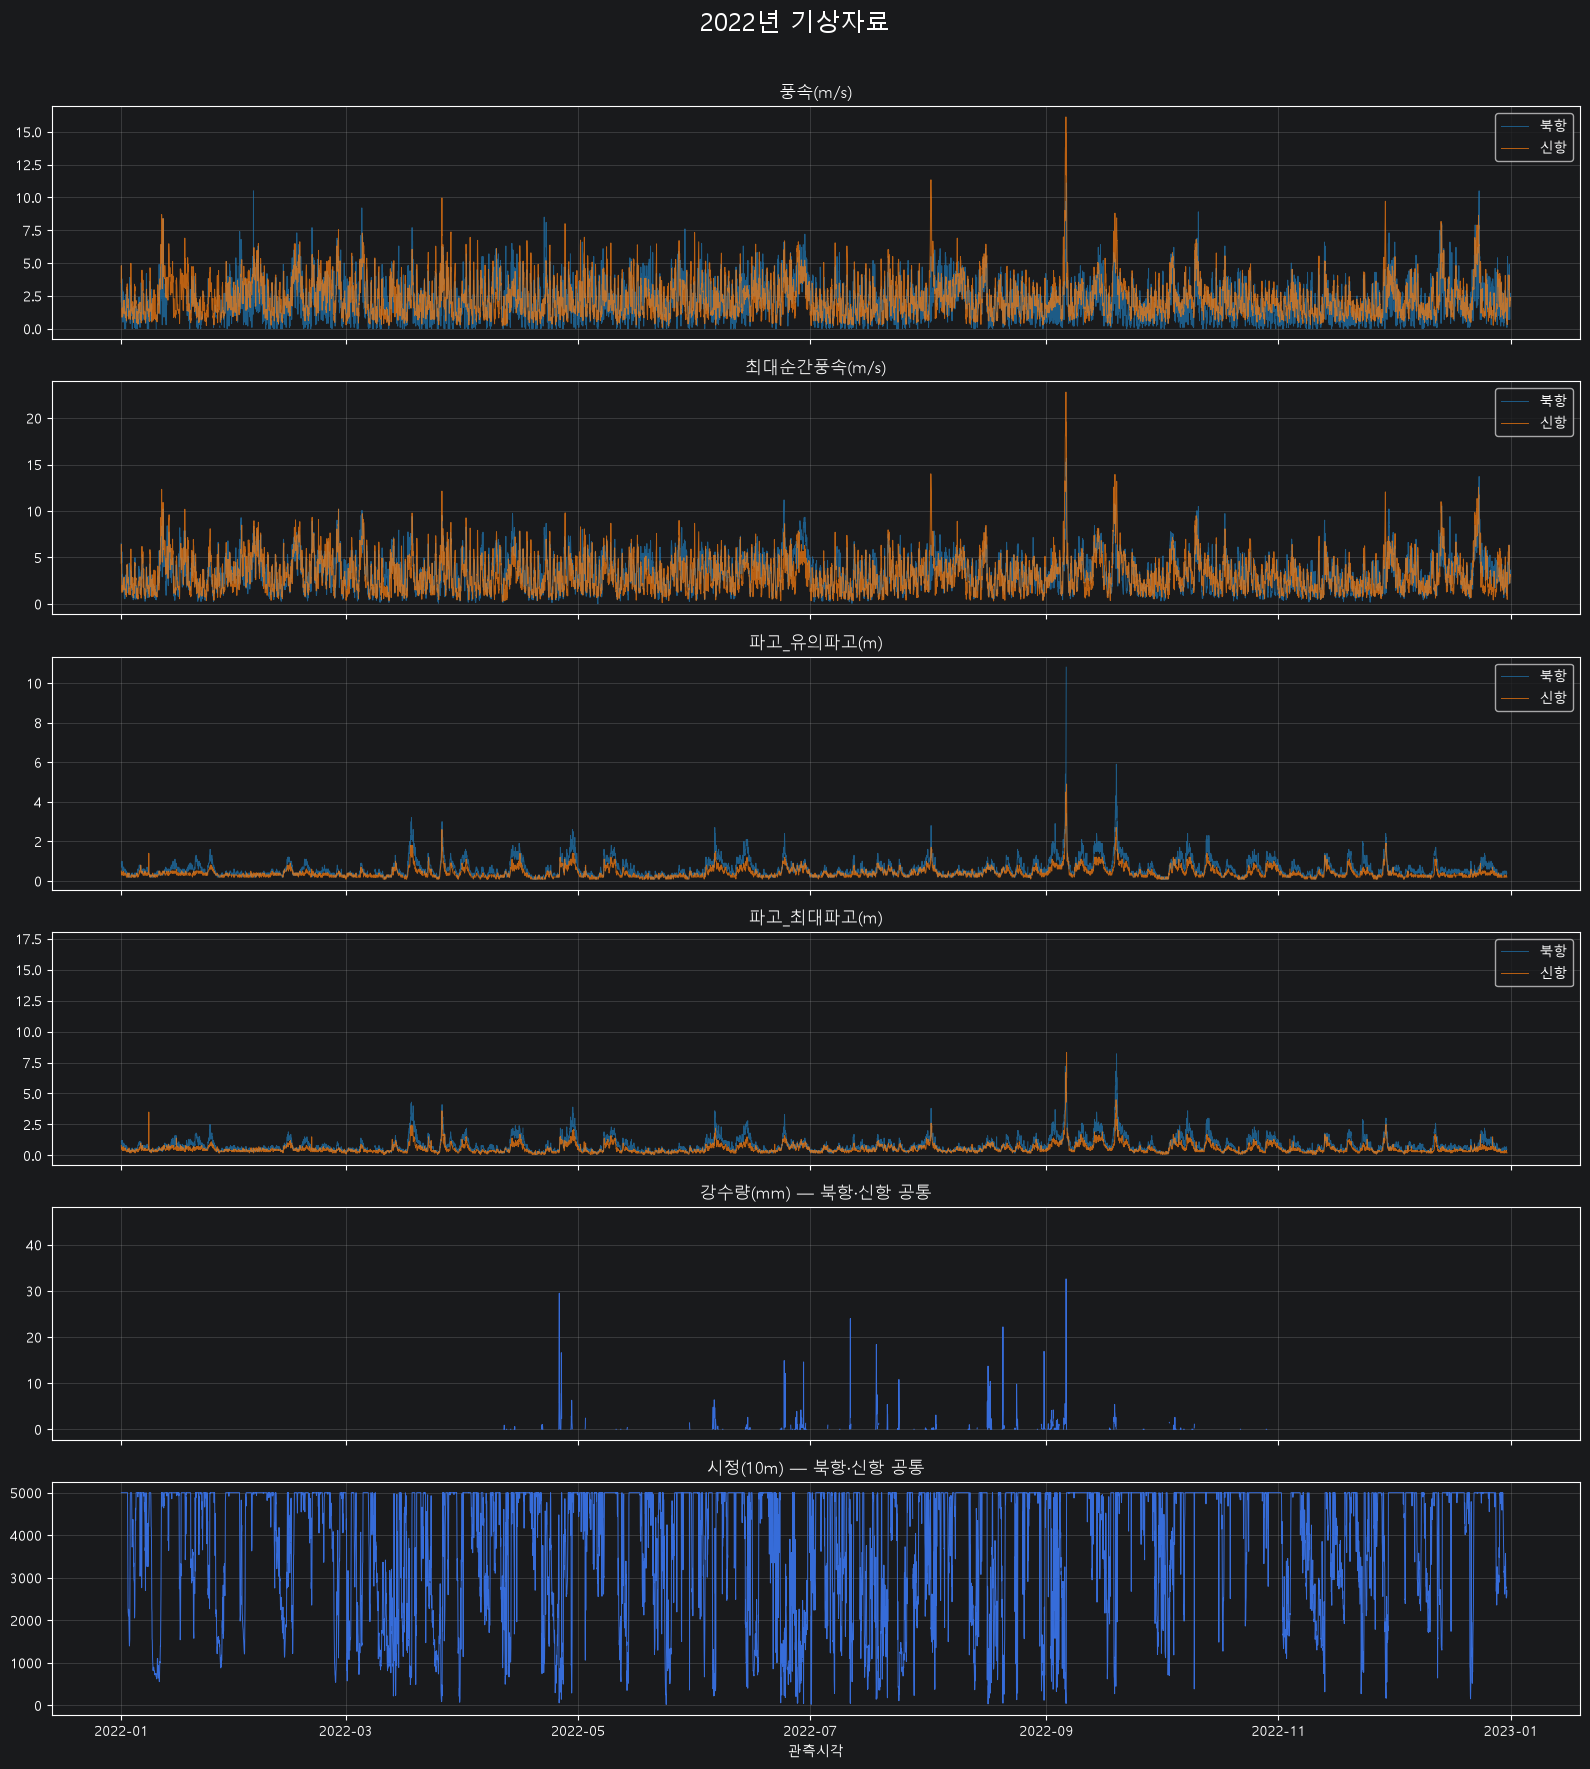

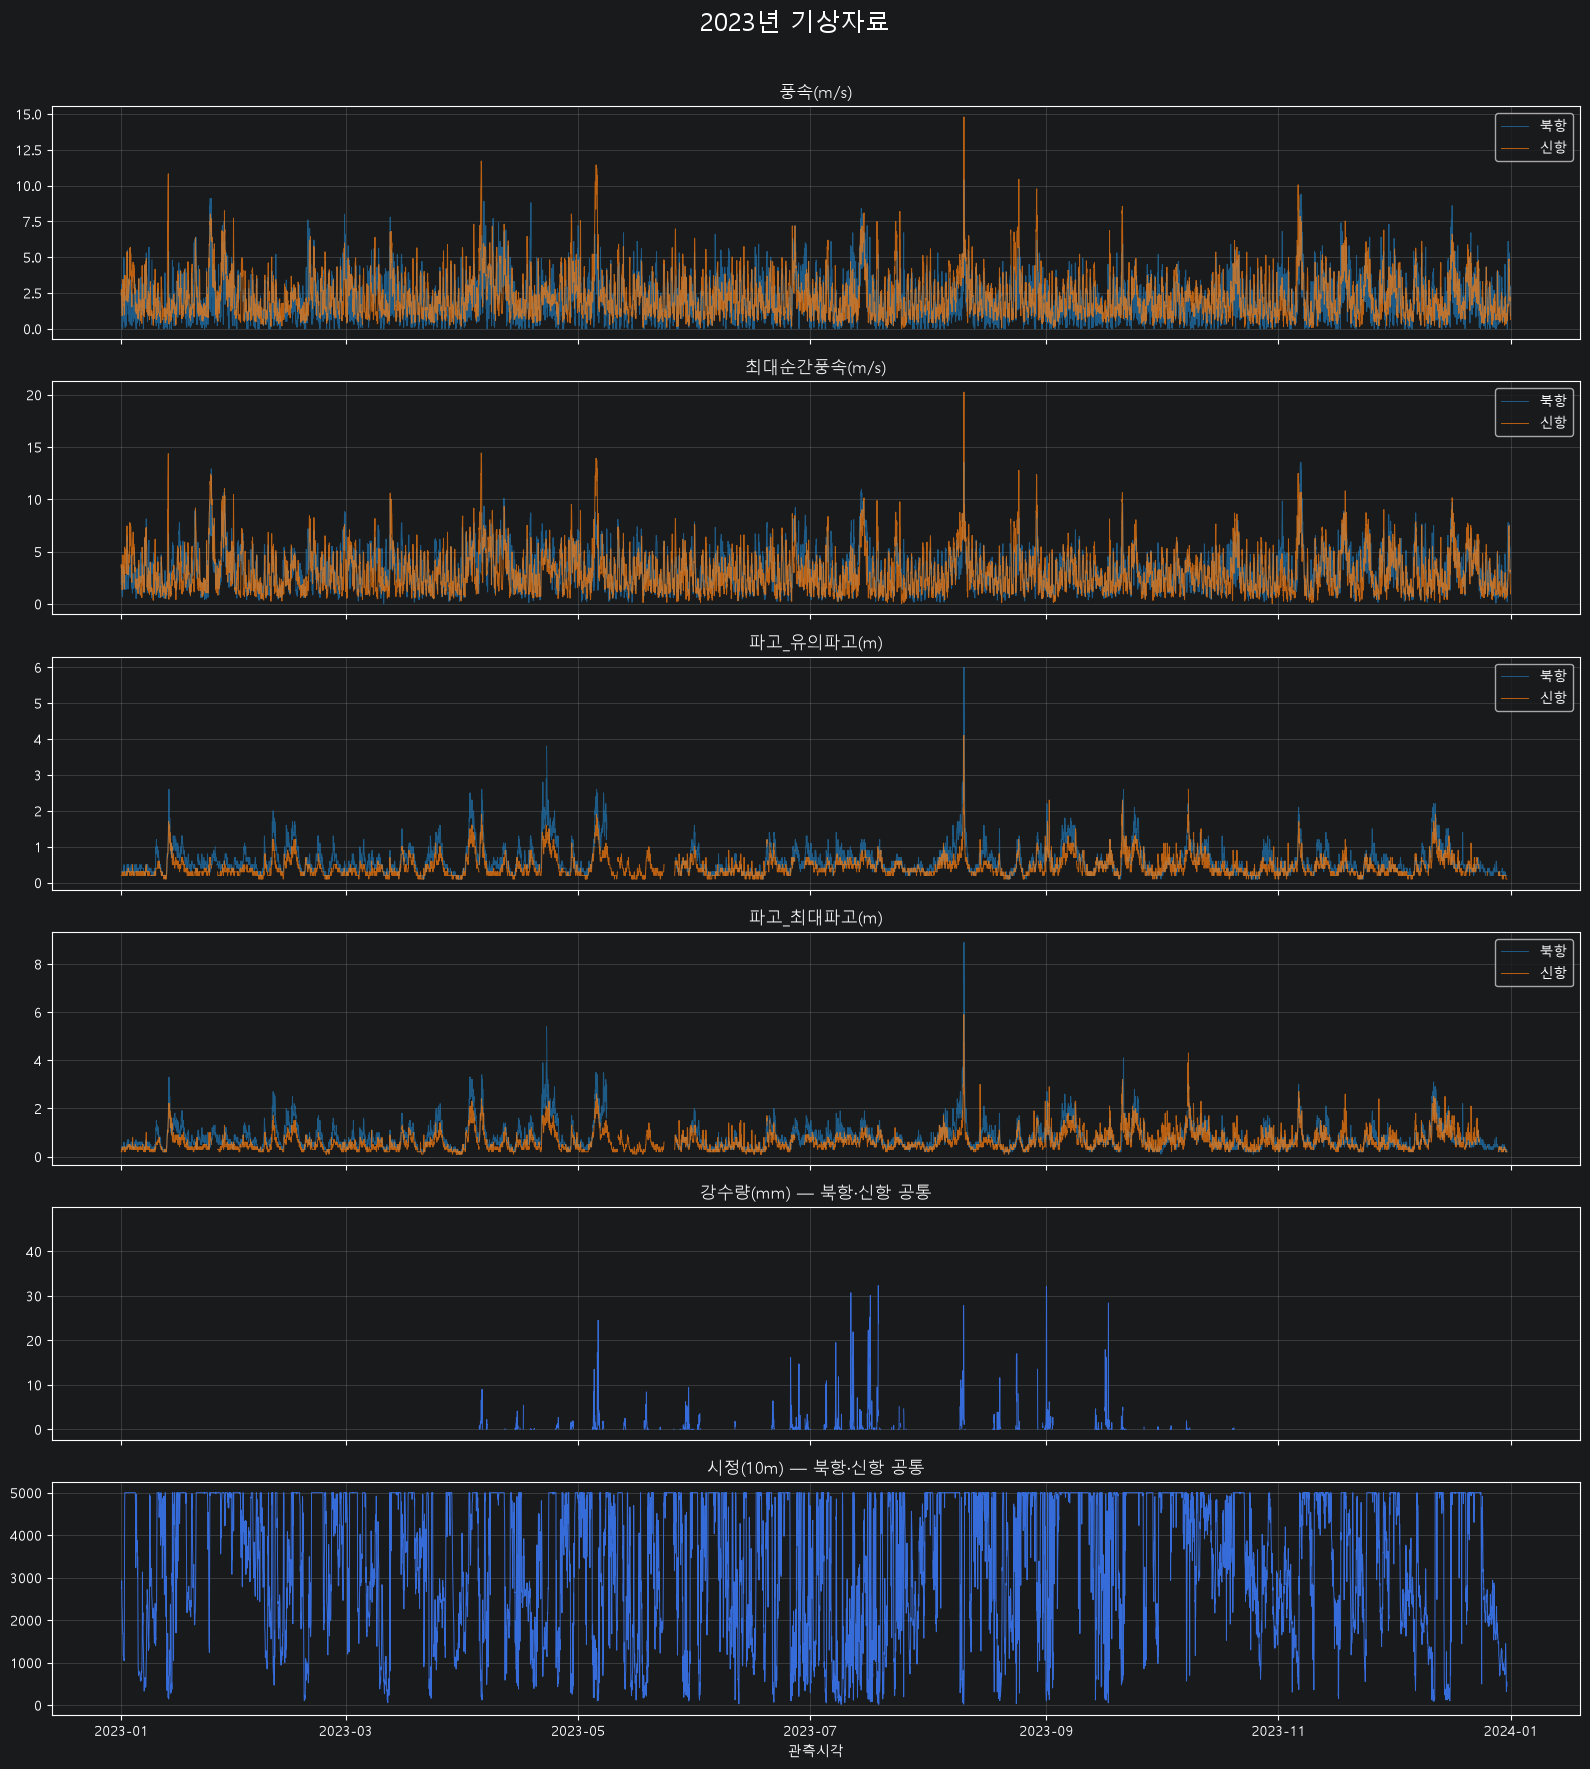

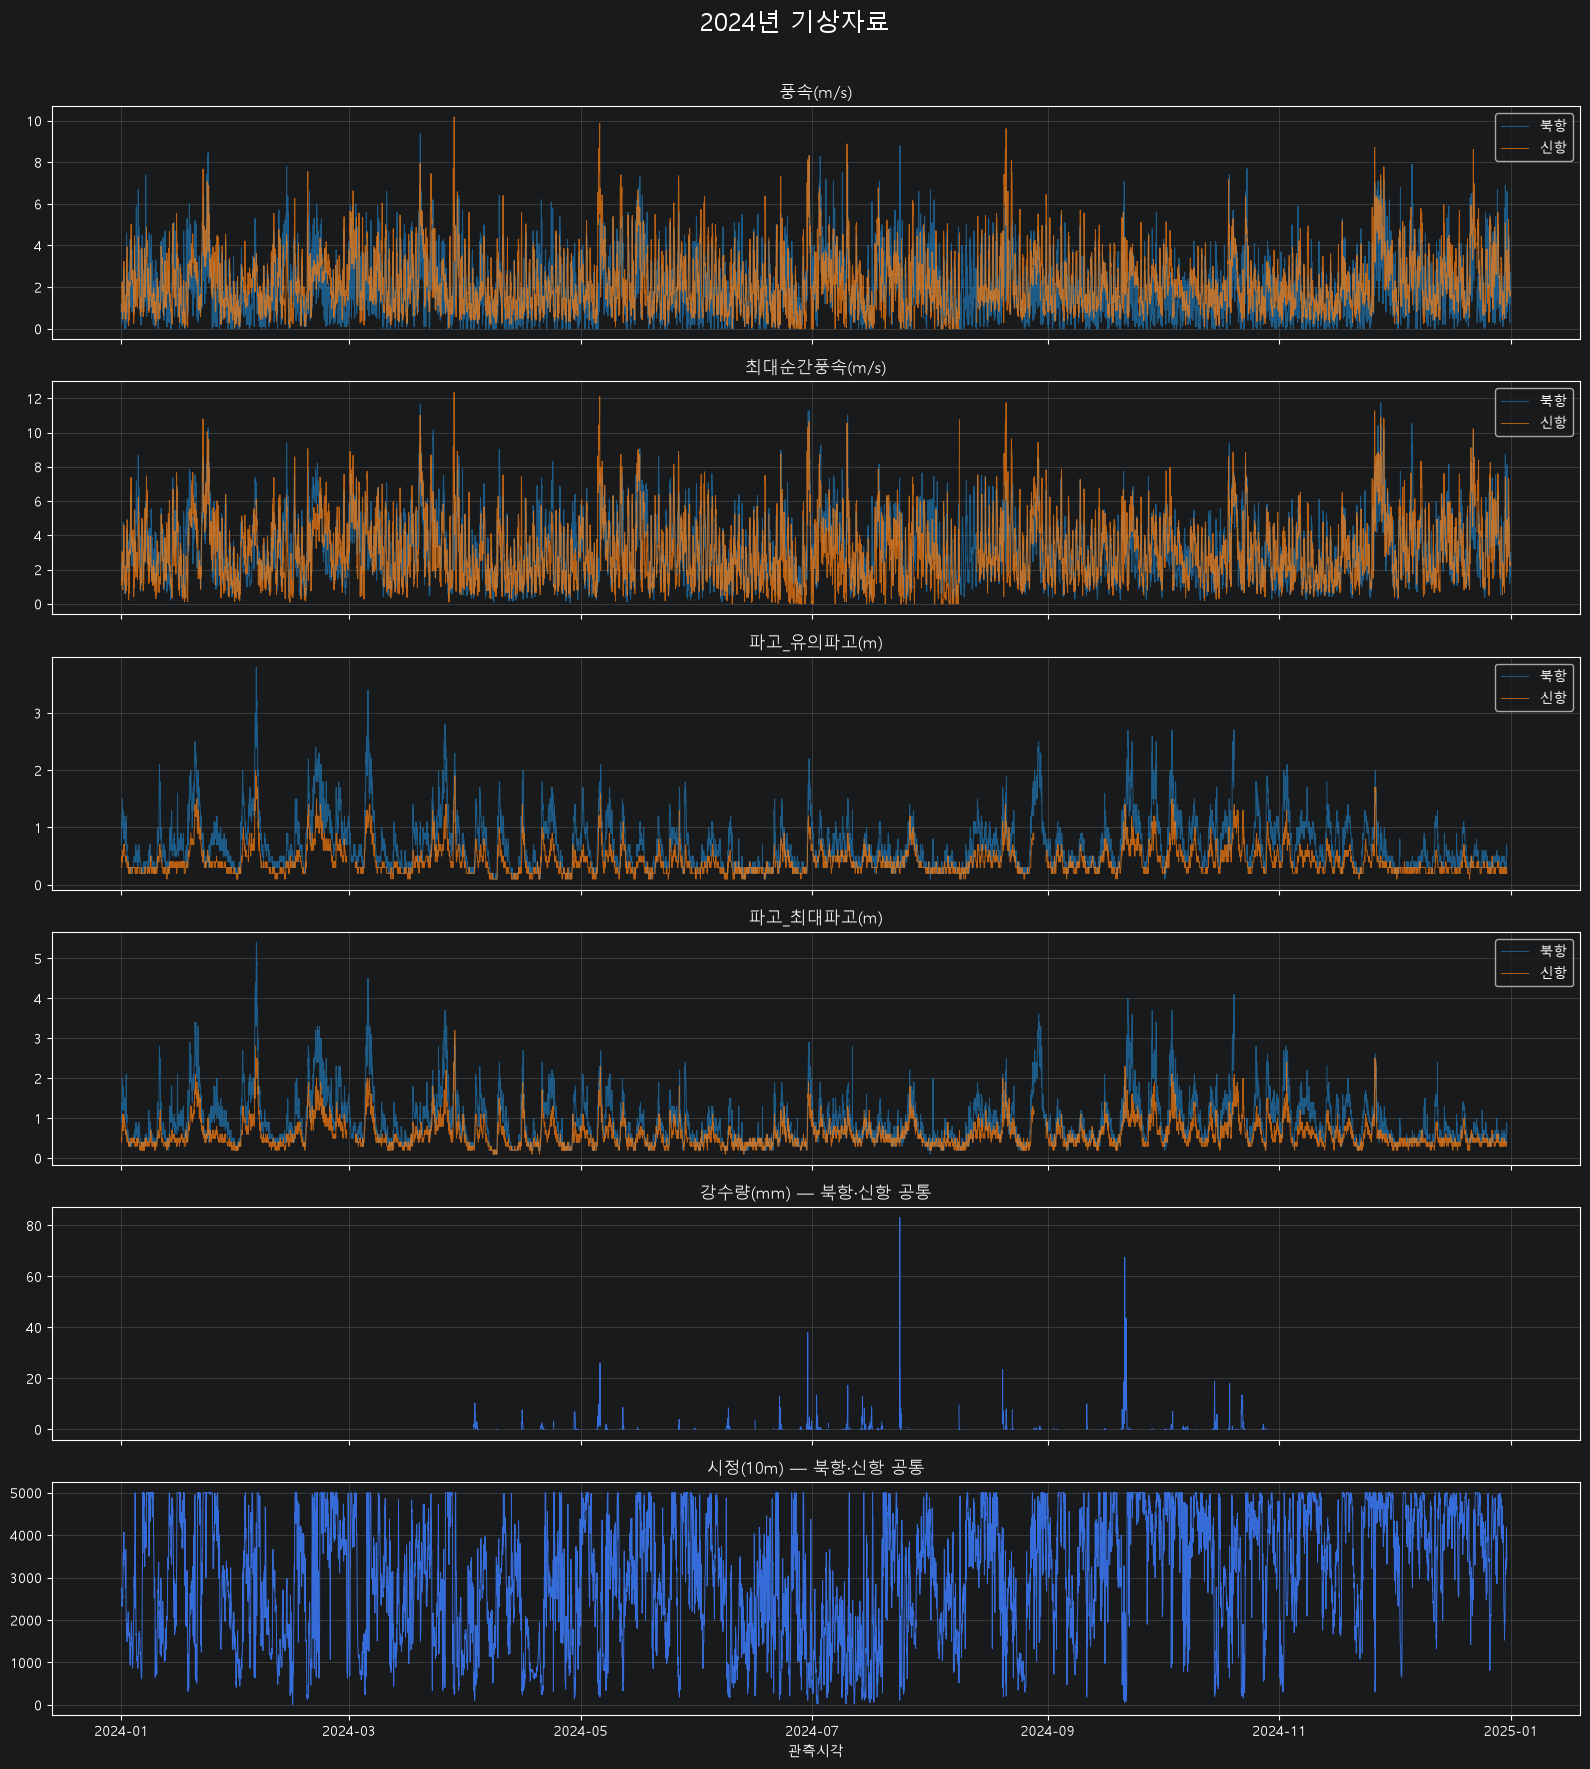

In [21]:
data = df1.copy()
data["관측시각"] = pd.to_datetime(data["관측시각"])
data = data.sort_values("관측시각")

port_columns = [
    "풍속(m/s)",
    "최대순간풍속(m/s)",
    "파고_유의파고(m)",
    "파고_최대파고(m)",
]

visibility = "시정(10m)" if "시정(10m)" in data.columns else "시정"
shared_columns = ["강수량(mm)", visibility]

colors = {"북항": "tab:blue", "신항": "tab:orange"}

for year, year_data in data.groupby(data["관측시각"].dt.year):
    fig, axes = plt.subplots(6, 1, figsize=(16, 18), sharex=True)
    fig.suptitle(f"{year}년 기상자료", fontsize=18)

    for ax, column in zip(axes[:4], port_columns):
        for port, group in year_data.groupby("항만"):
            series = group.set_index("관측시각")[column].asfreq("h")

            ax.plot(
                series.index, series,
                label=port,
                color=colors.get(port),
                linewidth=0.7,
                alpha=0.7,
            )

        ax.set_title(column)
        ax.legend()
        ax.grid(alpha=0.3)

    shared = (
        year_data.groupby("관측시각")[shared_columns]
        .first()
        .asfreq("h")
    )

    for ax, column in zip(axes[4:], shared_columns):
        ax.plot(shared.index, shared[column], linewidth=0.7)
        ax.set_title(f"{column} — 북항·신항 공통")
        ax.grid(alpha=0.3)

    axes[-1].set_xlabel("관측시각")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

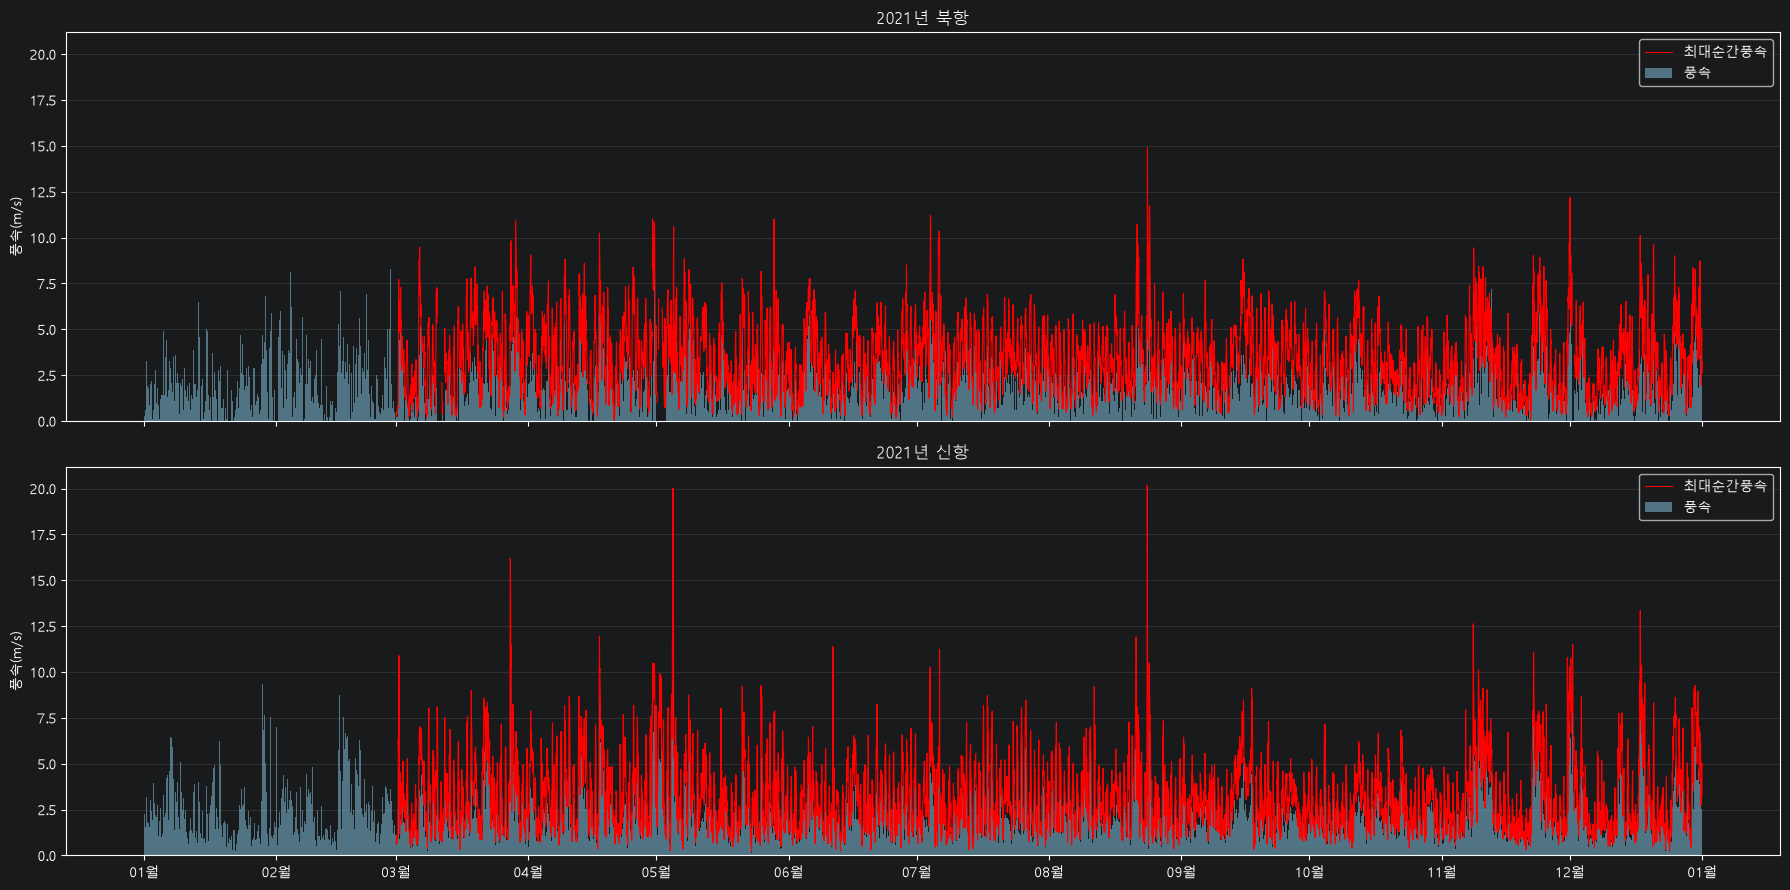

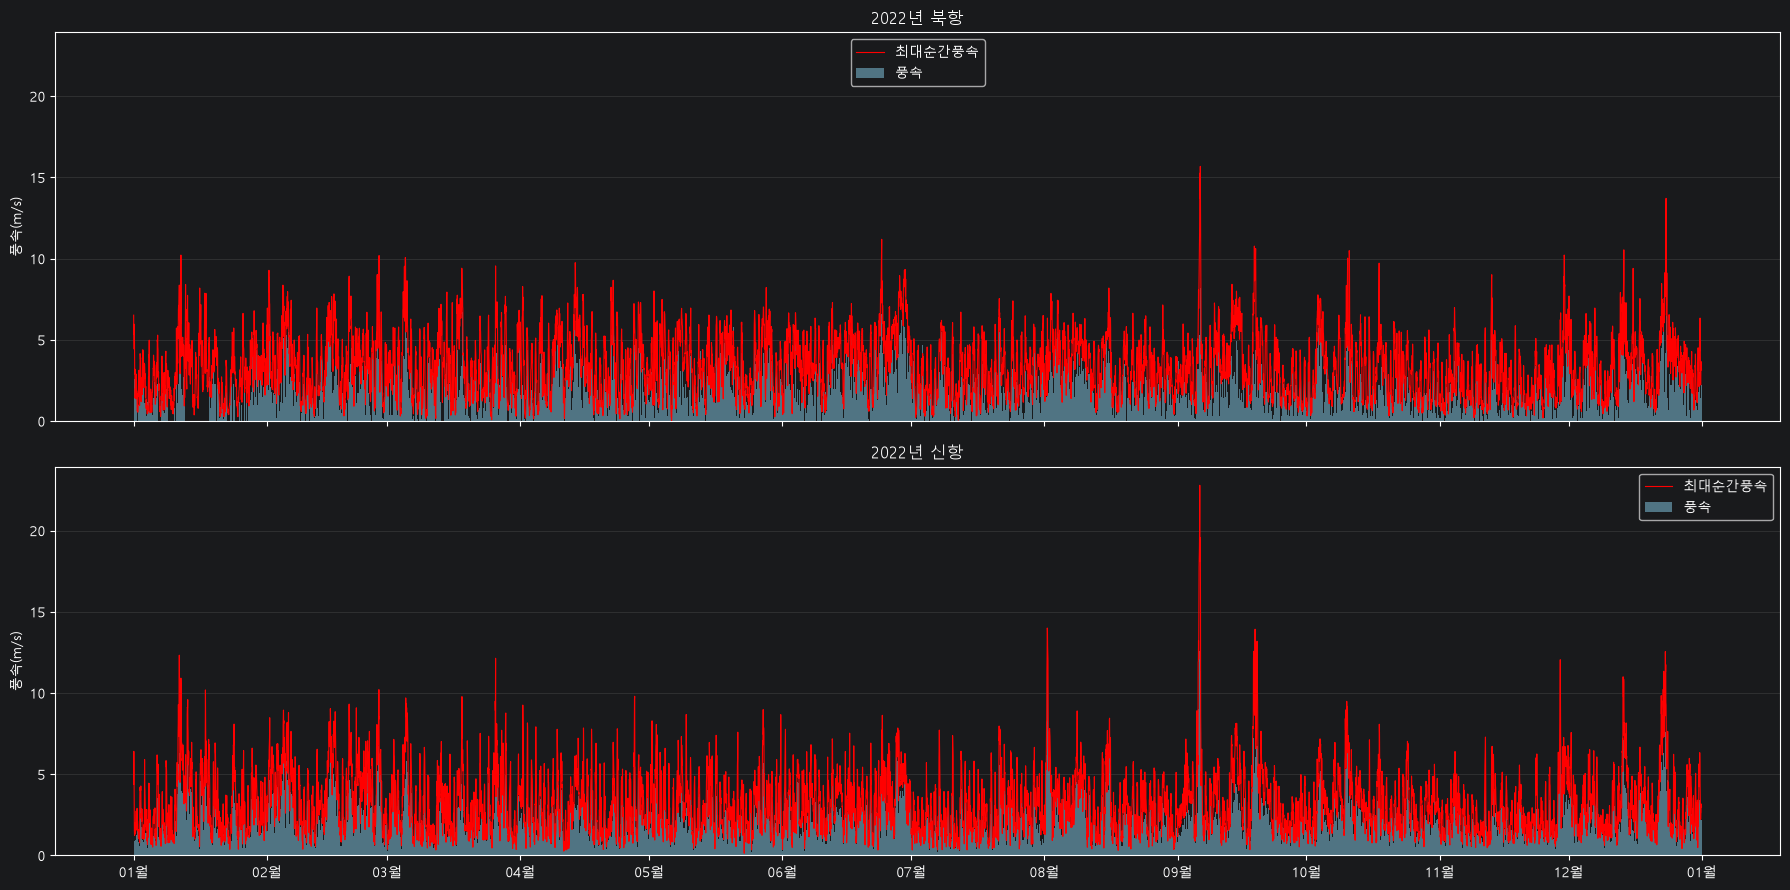

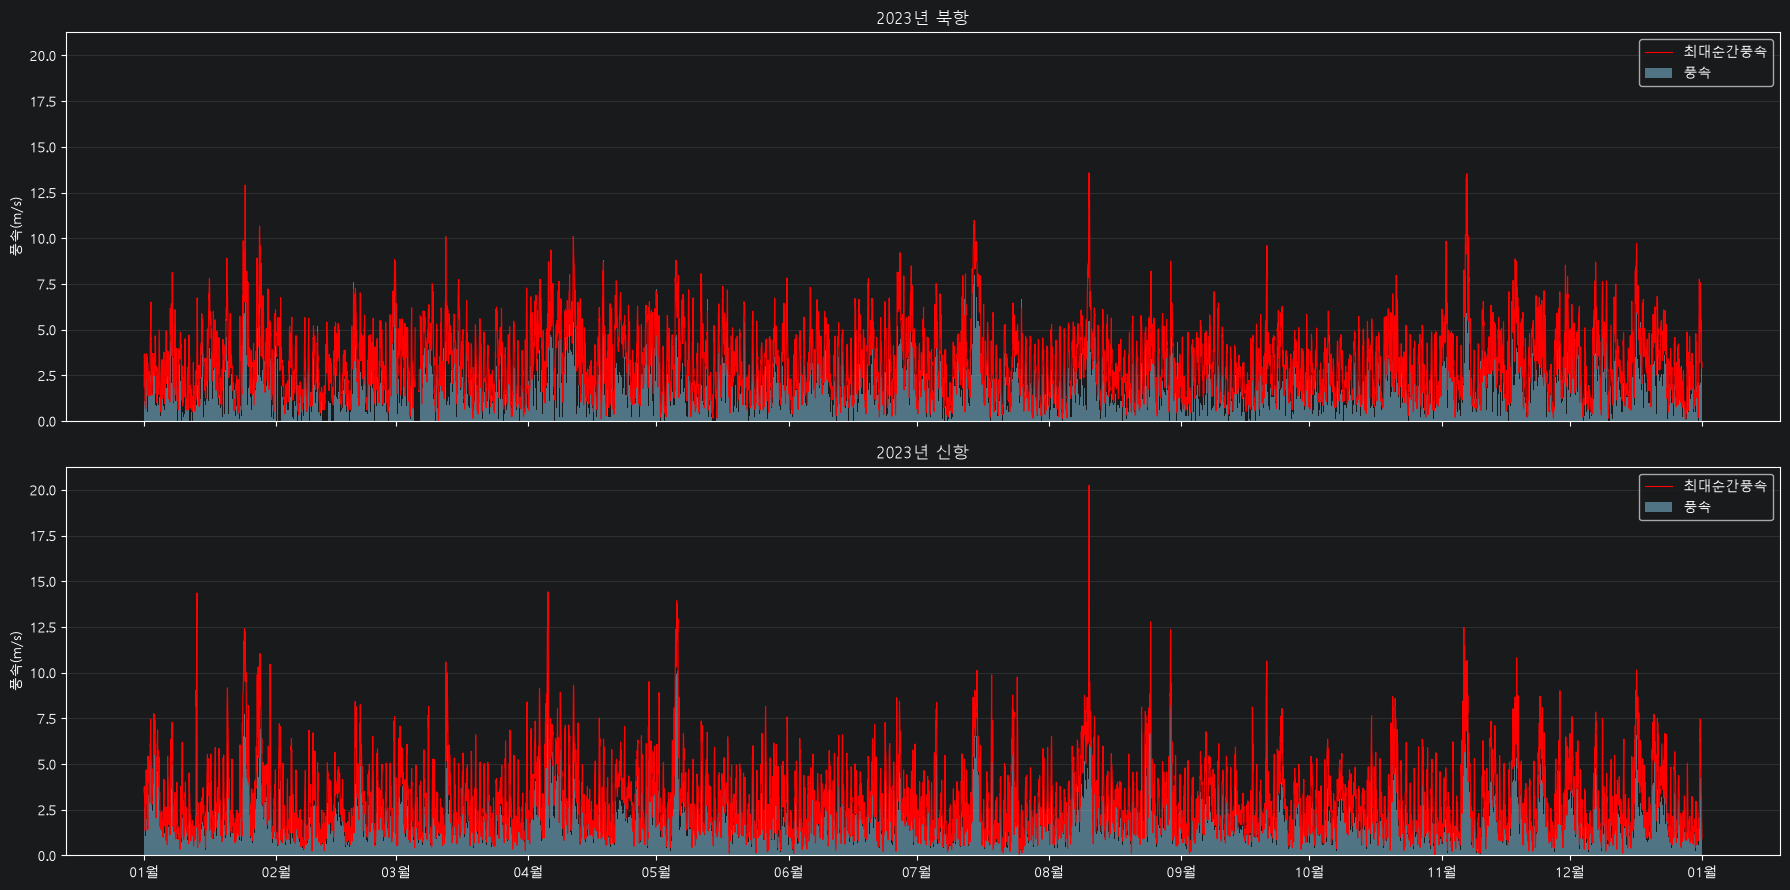

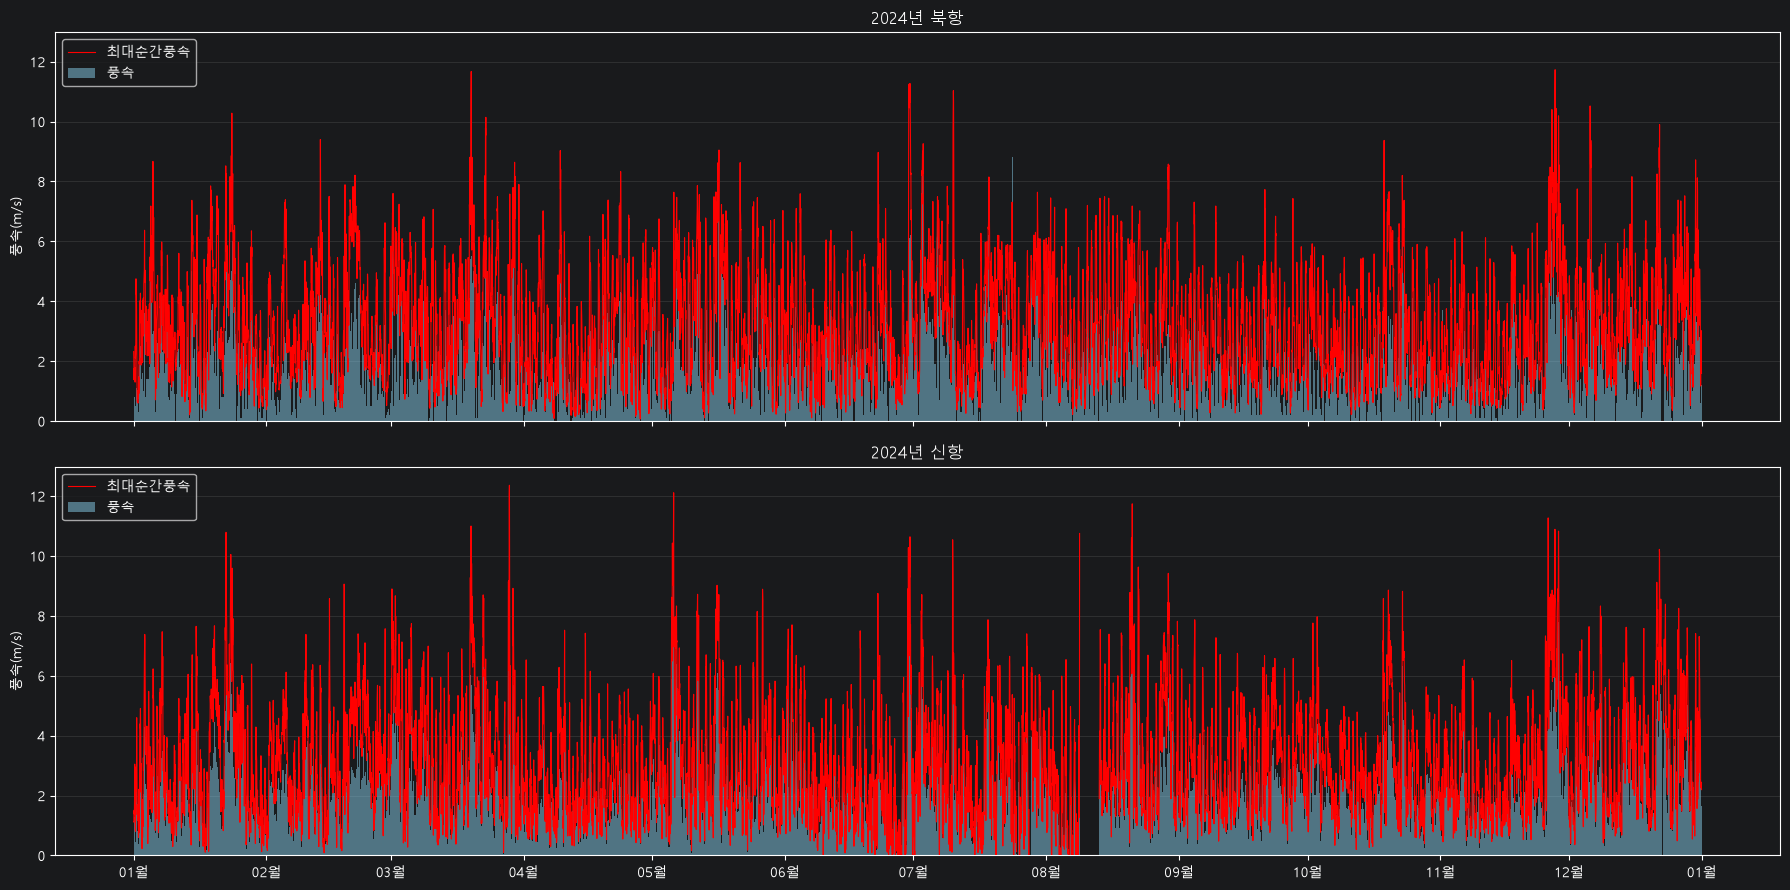

In [22]:
import matplotlib.dates as mdates

for year, year_data in data.groupby(data["관측시각"].dt.year):
    # 매번 새로운 그래프 생성
    fig, axes = plt.subplots(
        2, 1, figsize=(18, 9), sharex=True, sharey=True
    )

    for ax, port in zip(axes, ["북항", "신항"]):
        p = (
            year_data[year_data["항만"] == port]
            .set_index("관측시각")
            .sort_index()
            .asfreq("h")
        )

        ax.bar(
            p.index, p["풍속(m/s)"],
            width=1 / 24,
            color="skyblue", alpha=0.5,
            label="풍속", zorder=1,
        )

        ax.plot(
            p.index, p["최대순간풍속(m/s)"],
            color="red", linewidth=0.8,
            label="최대순간풍속", zorder=3,
        )

        ax.set_title(f"{year}년 {port}")
        ax.set_ylabel("풍속(m/s)")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m월"))

    fig.tight_layout()
    plt.show()

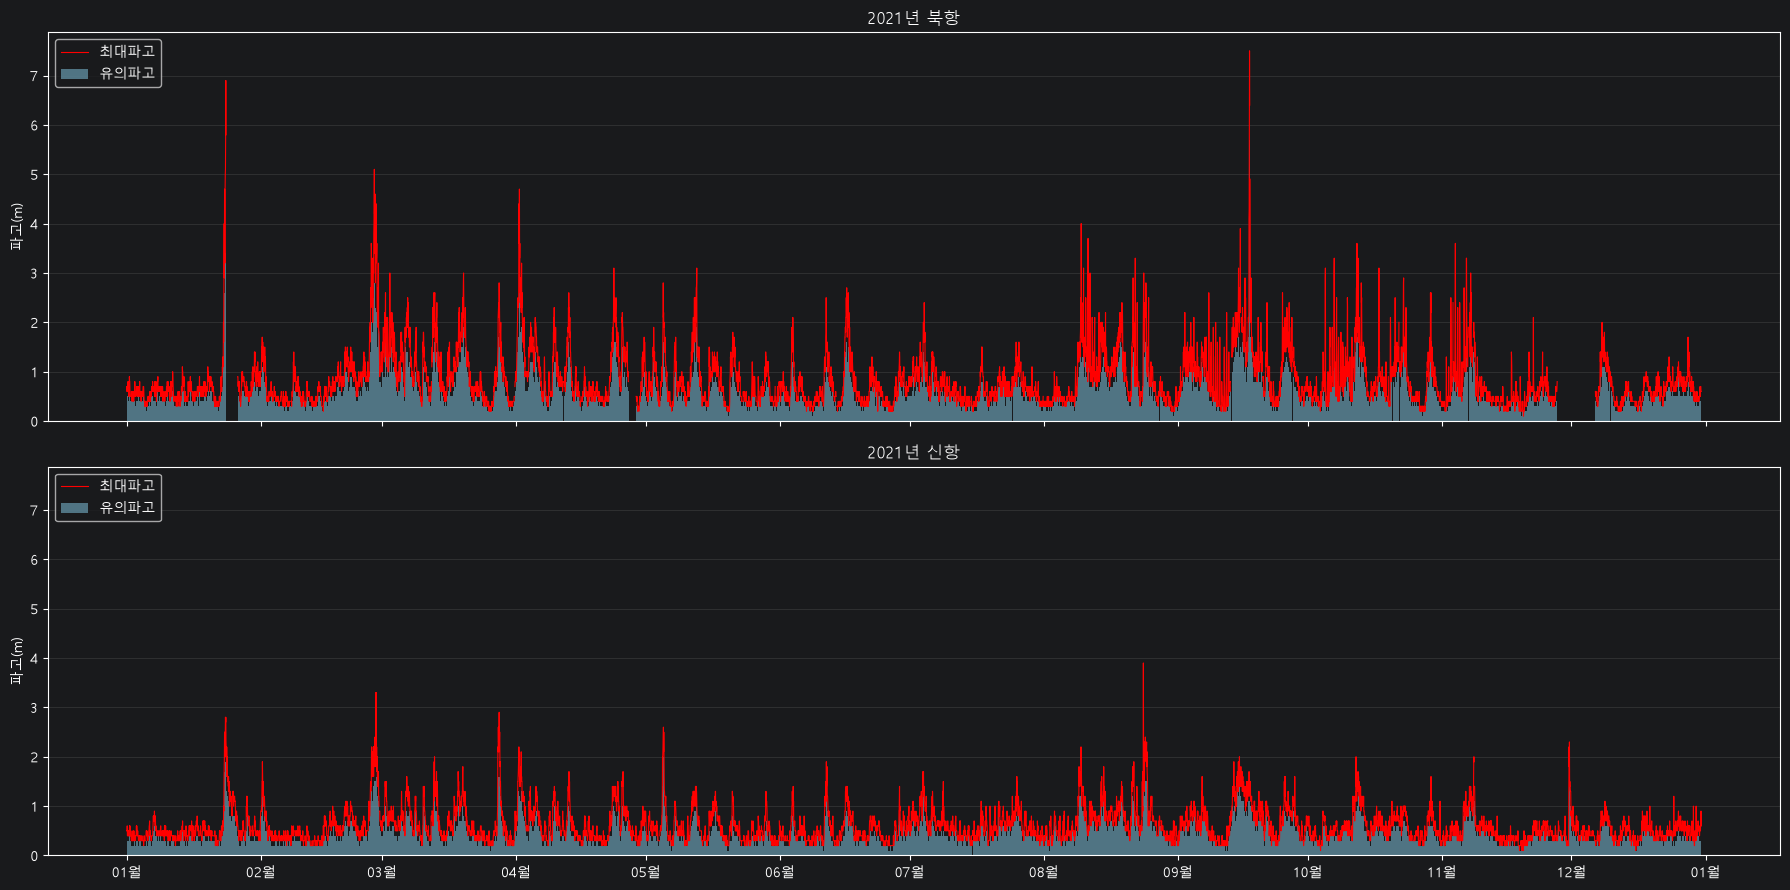

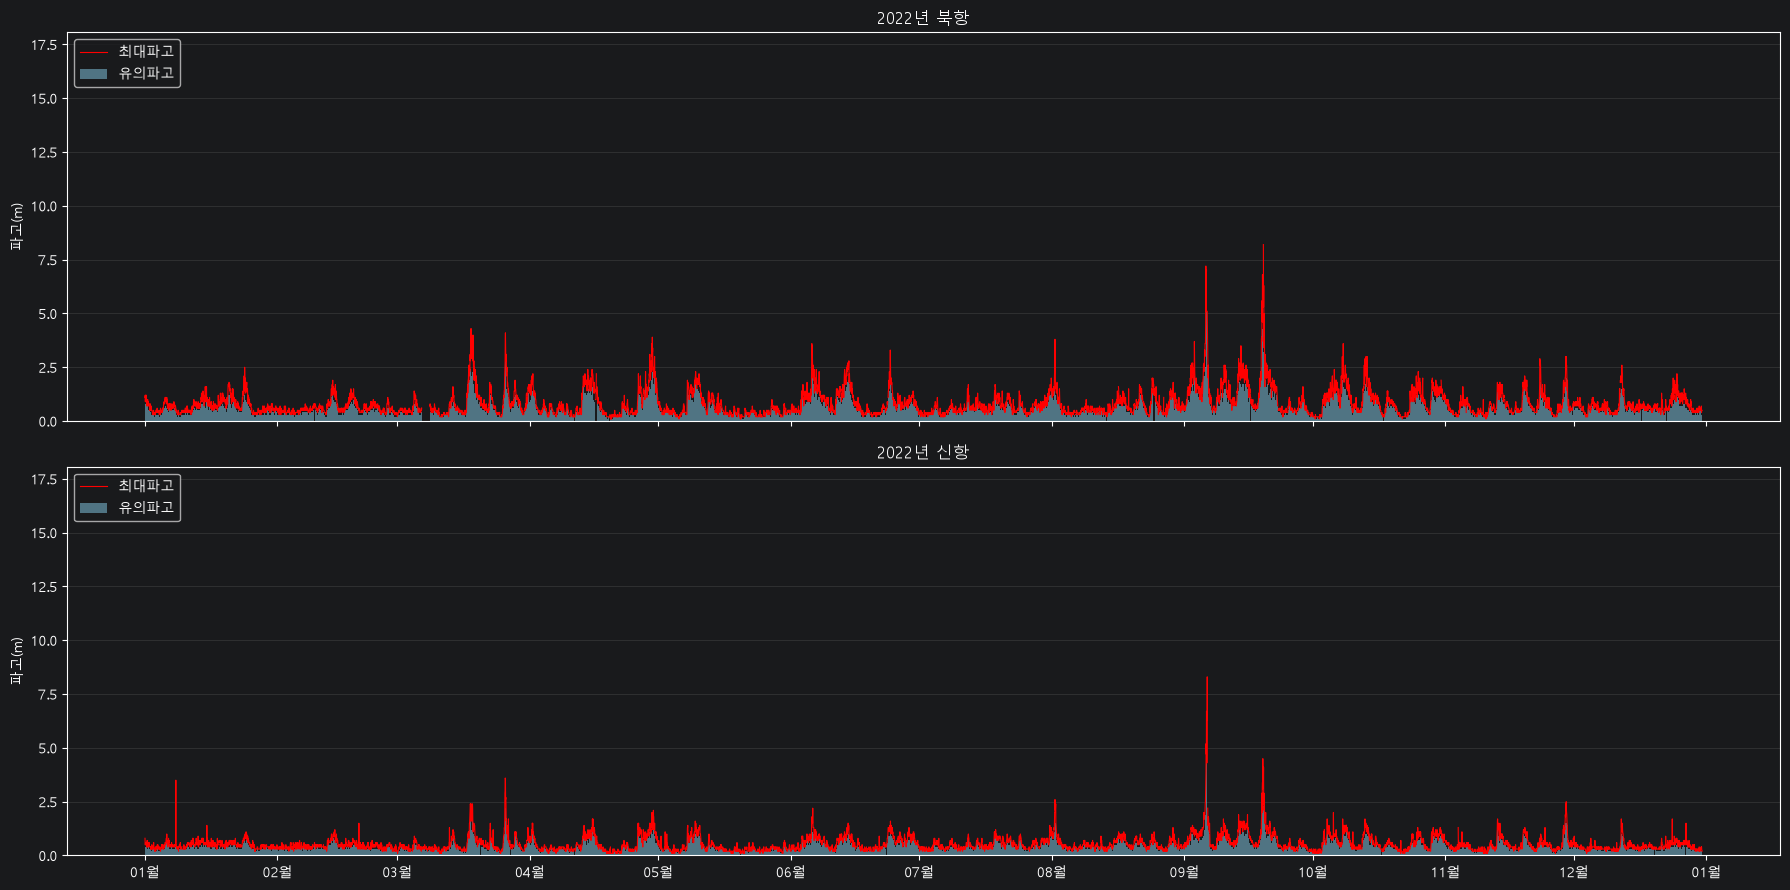

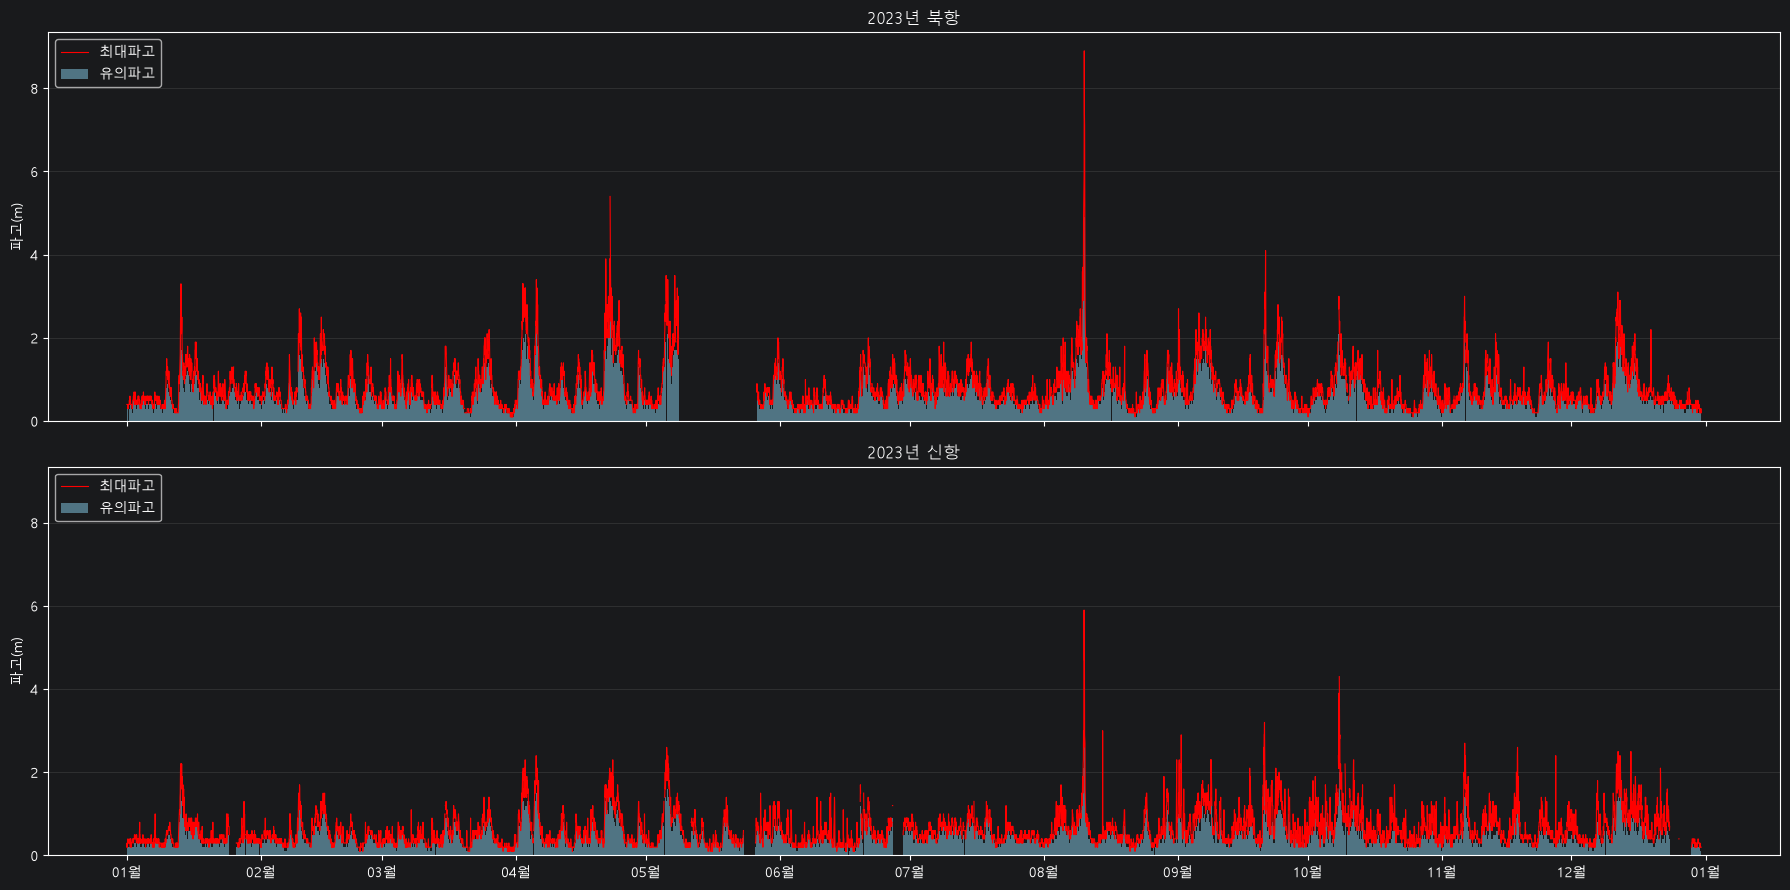

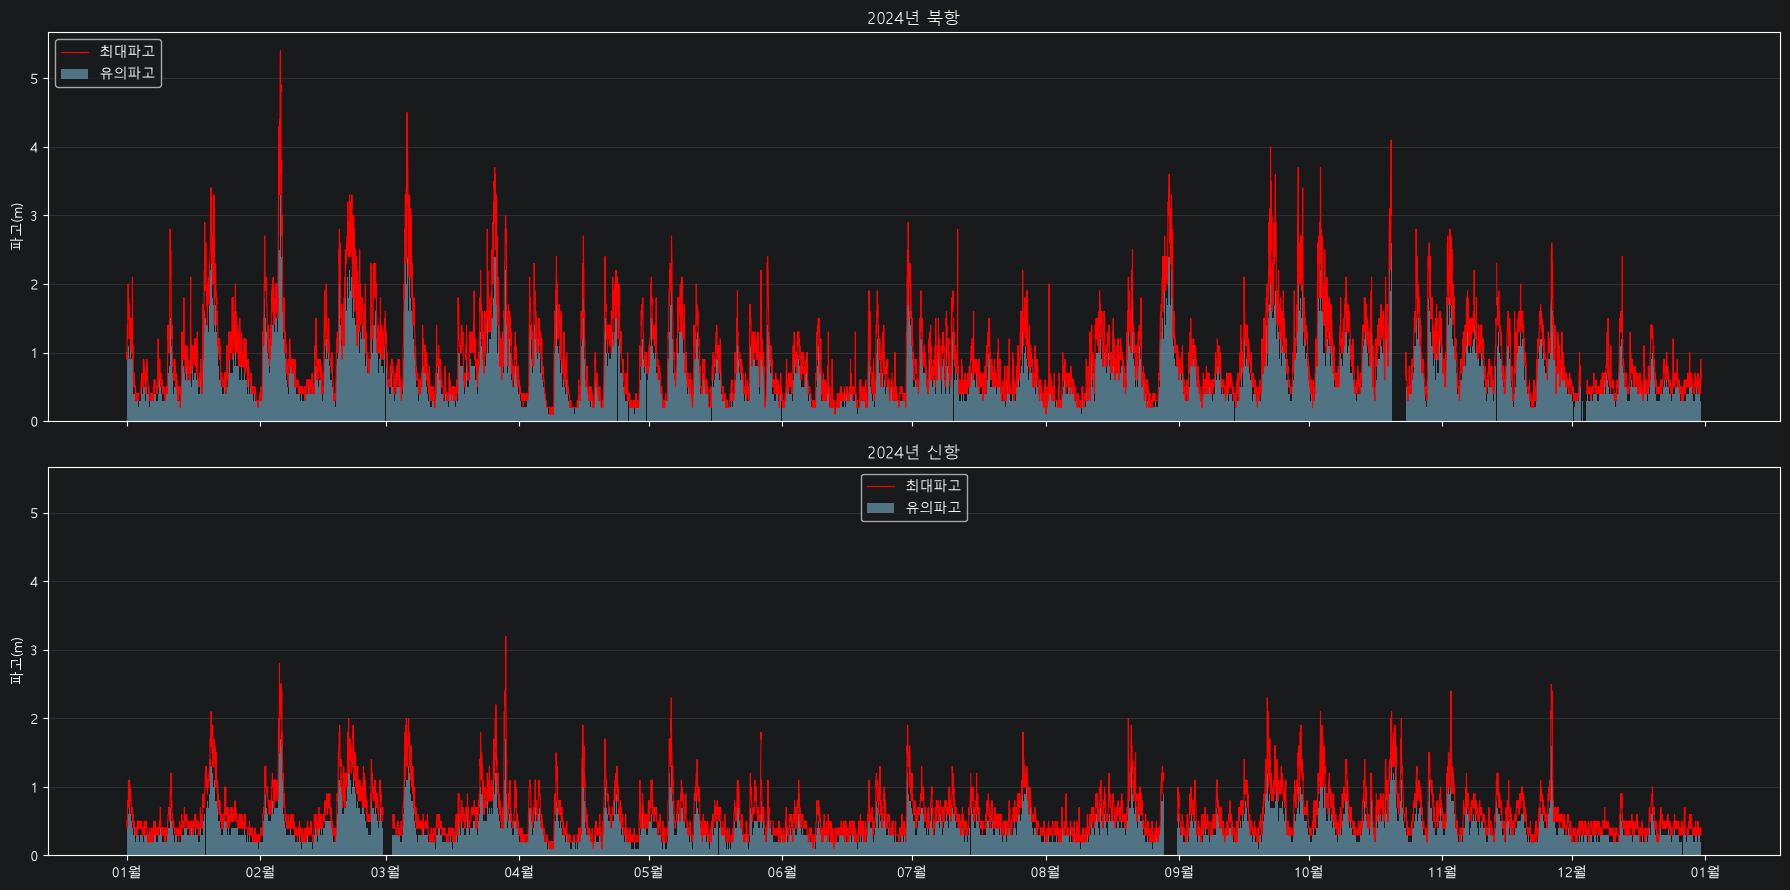

In [23]:
for year, year_data in data.groupby(data["관측시각"].dt.year):
    fig, axes = plt.subplots(
        2, 1, figsize=(18, 9), sharex=True, sharey=True
    )

    for ax, port in zip(axes, ["북항", "신항"]):
        p = (
            year_data[year_data["항만"] == port]
            .set_index("관측시각")
            .sort_index()
            .asfreq("h")
        )

        ax.bar(
            p.index, p["파고_유의파고(m)"],
            width=1 / 24,
            color="skyblue", alpha=0.5,
            label="유의파고", zorder=1,
        )

        ax.plot(
            p.index, p["파고_최대파고(m)"],
            color="red", linewidth=0.8,
            label="최대파고", zorder=3,
        )

        ax.set_title(f"{year}년 {port}")
        ax.set_ylabel("파고(m)")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m월"))

    fig.tight_layout()
    plt.show()

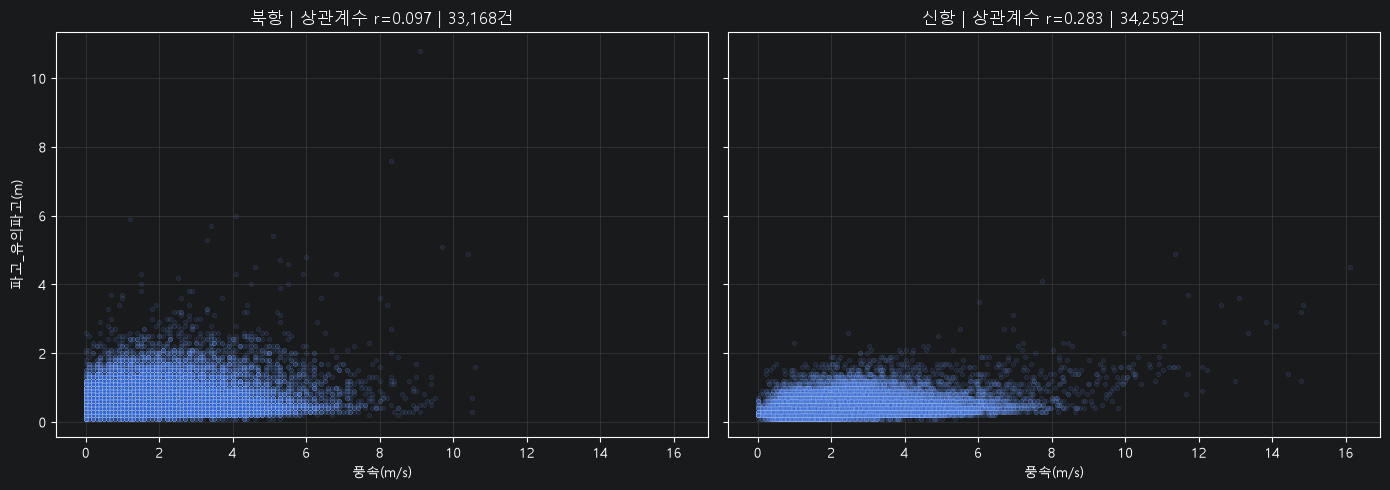

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, port in zip(axes, ["북항", "신항"]):
    p = df1.loc[
        df1["항만"] == port,
        ["풍속(m/s)", "파고_유의파고(m)"]
    ].dropna()

    corr = p["풍속(m/s)"].corr(p["파고_유의파고(m)"])

    sns.scatterplot(
        data=p,
        x="풍속(m/s)",
        y="파고_유의파고(m)",
        alpha=0.15,
        s=10,
        ax=ax,
    )

    ax.set_title(f"{port} | 상관계수 r={corr:.3f} | {len(p):,}건")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

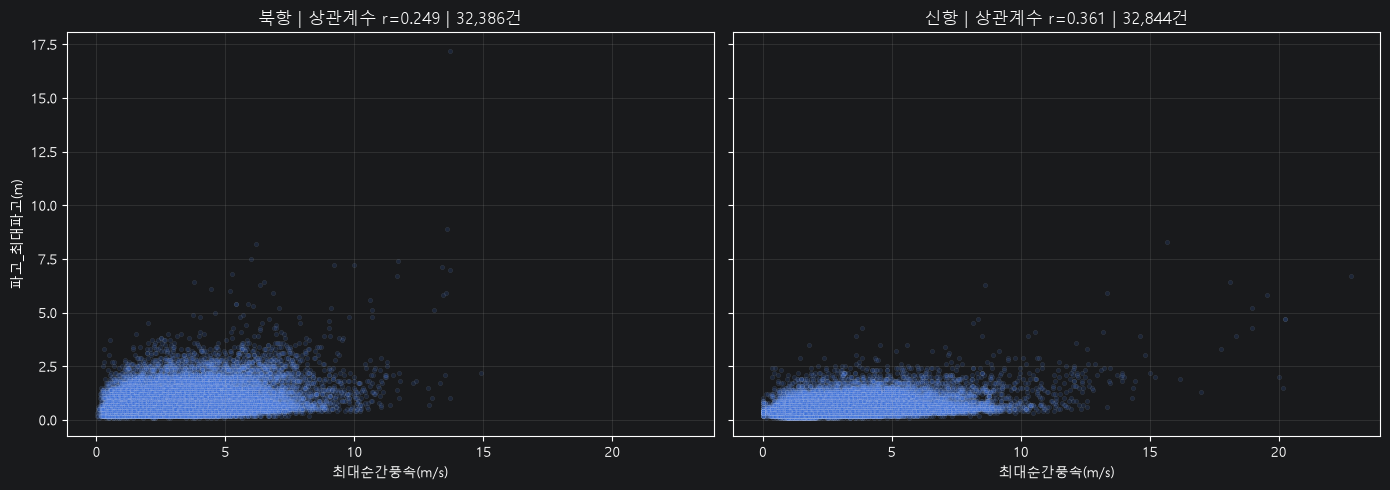

In [25]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, port in zip(axes, ["북항", "신항"]):
    p = df1.loc[
        df1["항만"] == port,
        ["최대순간풍속(m/s)", "파고_최대파고(m)"]
    ].dropna()

    corr = p.iloc[:, 0].corr(p.iloc[:, 1])

    sns.scatterplot(
        data=p,
        x="최대순간풍속(m/s)",
        y="파고_최대파고(m)",
        alpha=0.15,
        s=10,
        ax=ax,
    )

    ax.set_title(f"{port} | 상관계수 r={corr:.3f} | {len(p):,}건")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [26]:
# 강수량·시정은 두 항만이 같은 자료라 시간 중복 제거
p = df1[["관측시각", "강수량(mm)", "시정(10m)"]].copy()
p["관측시각"] = pd.to_datetime(p["관측시각"])
p = p.drop_duplicates("관측시각")

p["시간대"] = p["관측시각"].dt.hour

result = (
    p.groupby("시간대")[["강수량(mm)", "시정(10m)"]]
    .apply(lambda x: x["강수량(mm)"].corr(x["시정(10m)"]))
    .rename("상관계수")
    .round(3)
    .to_frame()
)

display(result)

,상관계수
시간대,
0,-0.325
1,-0.323
2,-0.196
3,-0.402
4,-0.353
5,-0.344
6,-0.267
7,-0.338
8,-0.266


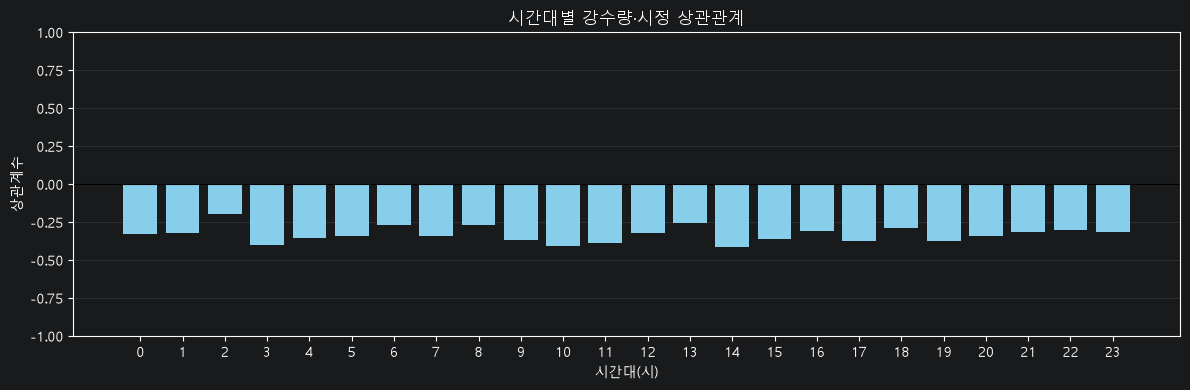

In [27]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.bar(result.index, result["상관계수"], color="skyblue")
ax.axhline(0, color="black", linewidth=0.8)

ax.set_xticks(range(24))
ax.set_xlabel("시간대(시)")
ax.set_ylabel("상관계수")
ax.set_title("시간대별 강수량·시정 상관관계")
ax.set_ylim(-1, 1)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


모든 시간대에서 강수량과 시정 사이에 음의 상관관계가 나타났다. 이는 강수량이 증가할수록 시정이 감소하는 경향을 의미하며, 상관계수는 시간대별로 약 −0.2~−0.4 수준이었다.

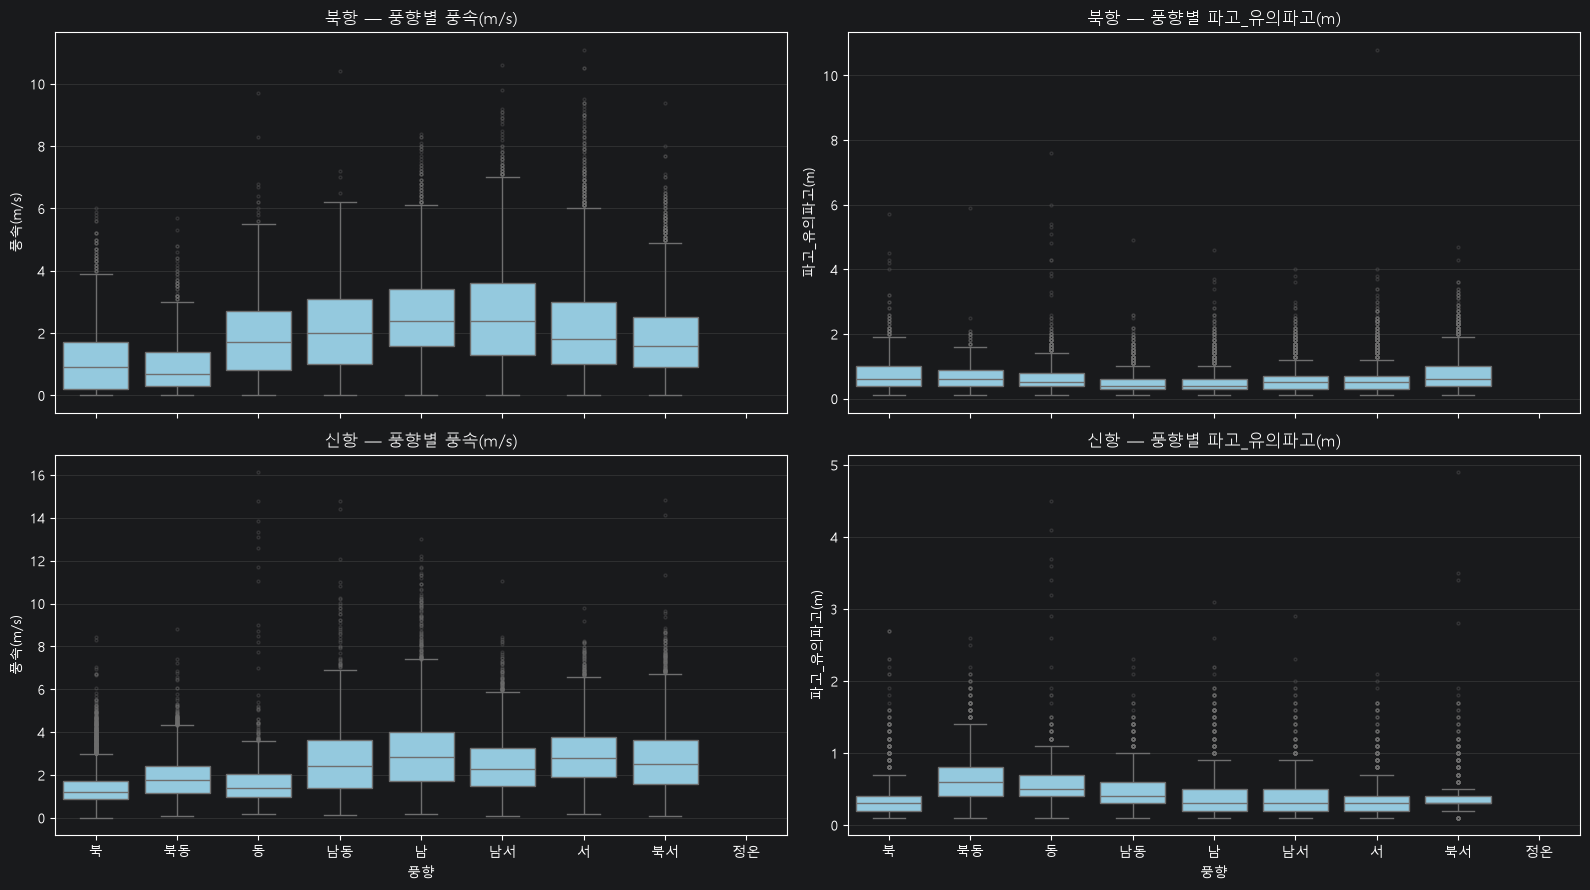

In [28]:
order = ["북", "북동", "동", "남동", "남", "남서", "서", "북서", "정온"]

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)

for i, port in enumerate(["북항", "신항"]):
    p = df1[df1["항만"] == port]

    for j, column in enumerate(["풍속(m/s)", "파고_유의파고(m)"]):
        sns.boxplot(
            data=p,
            x="풍향(8방위)",
            y=column,
            order=order,
            color="skyblue",
            flierprops={"markersize": 2, "alpha": 0.3},
            ax=axes[i, j],
        )

        axes[i, j].set_title(f"{port} — 풍향별 {column}")
        axes[i, j].set_xlabel("풍향")
        axes[i, j].set_ylabel(column)
        axes[i, j].set_axisbelow(True)
        axes[i, j].grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

- 북항은 남서풍·남풍, 신항은 남풍·서풍에서 풍속 중앙값이 상대적으로 높게 나타났다.
- 유의파고는 두 항만 모두 북동풍·동풍에서 상대적으로 높게 나타났다.
- 이는 풍속이 강한 방향과 파고가 높은 방향이 다를 수 있음을 보여주며, 풍속과 파고의 관계 분석 시 풍향을 함께 고려할 필요가 있다.

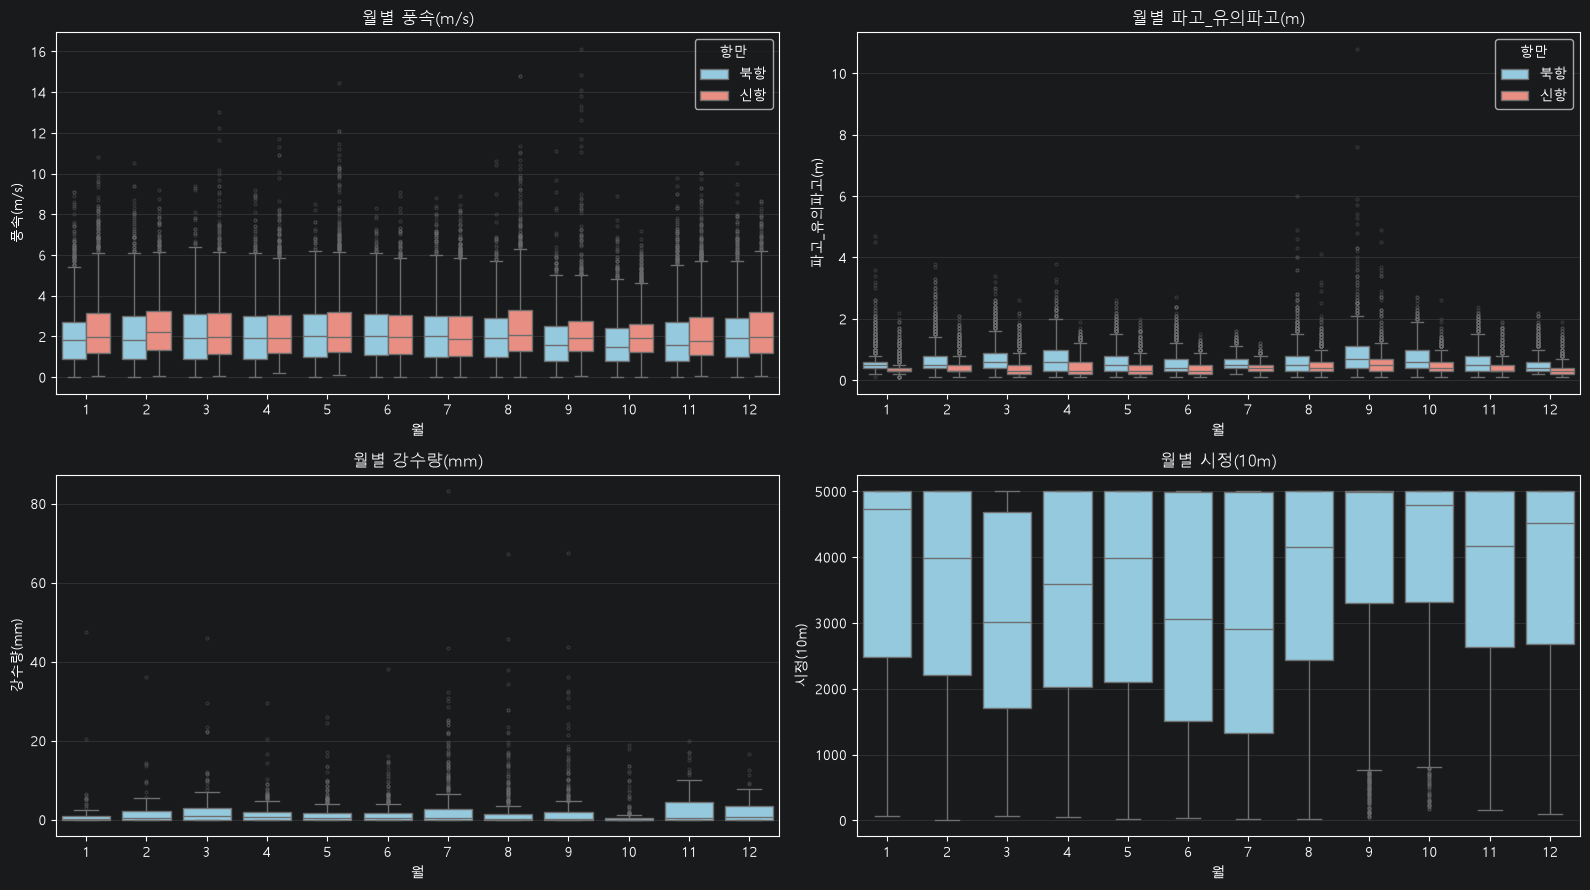

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

data = df1.copy()
data["관측시각"] = pd.to_datetime(data["관측시각"])
data["월"] = data["관측시각"].dt.month

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# 항만별 관측자료
for ax, column in zip(
    axes[0],
    ["풍속(m/s)", "파고_유의파고(m)"]
):
    sns.boxplot(
        data=data,
        x="월", y=column, hue="항만",
        order=range(1, 13),
        hue_order=["북항", "신항"],
        palette={"북항": "skyblue", "신항": "salmon"},
        flierprops={"markersize": 2, "alpha": 0.3},
        ax=ax,
    )
    ax.set_title(f"월별 {column}")

# 두 항만이 공유하는 관측자료
shared = data.drop_duplicates("관측시각")

for ax, column in zip(
    axes[1],
    ["강수량(mm)", "시정(10m)"]
):
    sns.boxplot(
        data=shared,
        x="월", y=column,
        order=range(1, 13),
        color="skyblue",
        flierprops={"markersize": 2, "alpha": 0.3},
        ax=ax,
    )
    ax.set_title(f"월별 {column}")

for ax in axes.flat:
    ax.set_xlabel("월")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

- 북항은 신항보다 대부분의 월에서 풍속·유의파고 중앙값이 높았으며, 유의파고는 8~9월에 큰 극단값이 관측되었다.
- 강수량은 7~9월에 큰 관측값이 나타났고, 시정 중앙값은 3월과 6~7월에 상대적으로 낮았다.
- 다만 강수량은 결측치를 제외한 분포이므로, 이 그래프만으로 월별 총강수량이나 비가 온 빈도를 비교할 수는 없다.

In [30]:
# 풍속·파고: 항만별 상위 5건
for column in [
    "풍속(m/s)", "최대순간풍속(m/s)",
    "파고_유의파고(m)", "파고_최대파고(m)"
]:
    print(f"\n▶ {column} 상위 5건")

    for port in ["북항", "신항"]:
        p = df1[df1["항만"] == port]
        display(
            p.nlargest(5, column)[["항만", "관측시각", column]]
        )

# 강수량·시정: 공통 관측자료의 시간 중복 제거
shared = df1.drop_duplicates("관측시각")

print("\n▶ 강수량 상위 5건")
display(
    shared.nlargest(5, "강수량(mm)")[
        ["관측시각", "강수량(mm)"]
    ]
)

print("\n▶ 시정 하위 5건")
display(
    shared.nsmallest(5, "시정(10m)")[
        ["관측시각", "시정(10m)"]
    ]
)


▶ 풍속(m/s) 상위 5건


,항만,관측시각,풍속(m/s)
46998,북항,2022-09-06 07:00:00,11.1
28842,북항,2021-08-24 01:00:00,10.6
36748,북항,2022-02-04 18:00:00,10.5
52202,북항,2022-12-23 17:00:00,10.5
63228,북항,2023-08-10 10:00:00,10.4


,항만,관측시각,풍속(m/s)
46993,신항,2022-09-06 04:00:00,16.13
46999,신항,2022-09-06 07:00:00,14.85
28841,신항,2021-08-24 00:00:00,14.80
63227,신항,2023-08-10 09:00:00,14.79
23507,신항,2021-05-04 21:00:00,14.43



▶ 최대순간풍속(m/s) 상위 5건


,항만,관측시각,최대순간풍속(m/s)
46998,북항,2022-09-06 07:00:00,15.68
46994,북항,2022-09-06 05:00:00,15.26
28842,북항,2021-08-24 01:00:00,14.92
46996,북항,2022-09-06 06:00:00,13.72
46992,북항,2022-09-06 04:00:00,13.71


,항만,관측시각,최대순간풍속(m/s)
46993,신항,2022-09-06 04:00:00,22.79
46991,신항,2022-09-06 03:00:00,20.25
63227,신항,2023-08-10 09:00:00,20.25
28841,신항,2021-08-24 00:00:00,20.18
23507,신항,2021-05-04 21:00:00,20.02


... (6 outputs left out)


▶ 강수량 상위 5건


,관측시각,강수량(mm)
79964,2024-07-24 02:00:00,83.1
82808,2024-09-21 08:00:00,67.5
28924,2021-08-25 18:00:00,67.1
53200,2023-01-13 12:00:00,47.6
39124,2022-03-26 06:00:00,45.9



▶ 시정 하위 5건


,관측시각,시정(10m)
72288,2024-02-15 04:00:00,11.0
24046,2021-05-16 03:00:00,14.0
26594,2021-07-08 05:00:00,16.0
61678,2023-07-09 03:00:00,16.0
62152,2023-07-19 00:00:00,19.0


In [31]:
# 이상 행 확인
mask = df1["풍속(m/s)"] > df1["최대순간풍속(m/s)"]

print(f"풍속이 최대순간풍속보다 큰 자료: {mask.sum():,}건")
display(
    df1.loc[mask, [
        "항만", "관측시각", "풍속(m/s)", "최대순간풍속(m/s)"
    ]]
)

풍속이 최대순간풍속보다 큰 자료: 2,482건


,항만,관측시각,풍속(m/s),최대순간풍속(m/s)
20394,북항,2021-03-01 01:00:00,0.6,0.25
20398,북항,2021-03-01 03:00:00,0.5,0.24
20410,북항,2021-03-01 09:00:00,1.3,0.83
20434,북항,2021-03-01 21:00:00,5.6,5.07
20494,북항,2021-03-03 03:00:00,1.8,1.37
...,...,...,...,...
87480,북항,2024-12-27 16:00:00,3.7,3.49
87520,북항,2024-12-28 12:00:00,6.7,6.17
87582,북항,2024-12-29 19:00:00,1.8,1.57
87596,북항,2024-12-30 02:00:00,2.5,2.00


In [32]:
check = df1.assign(
    비교가능=df1[["풍속(m/s)", "최대순간풍속(m/s)"]].notna().all(axis=1),
    풍속초과=df1["풍속(m/s)"] > df1["최대순간풍속(m/s)"]
)

result = check.groupby("항만")[["비교가능", "풍속초과"]].sum()
result["초과비율(%)"] = (
    result["풍속초과"] / result["비교가능"] * 100
).round(1)

display(result)

,비교가능,풍속초과,초과비율(%)
항만,,,
북항,32962,2482,7.5
신항,33501,0,0.0
